# Hôpital diabétique 130-US
### Apprentissage automatique — Préparation des données, segmentation et classification

---

## Présentation du projet

Ce projet analyse le jeu de données **Diabetes 130-US Hospitals for Years 1999–2008**, qui recense les séjours hospitaliers de patients diabétiques dans 130 hôpitaux américains.

L'objectif est de préparer les données, identifier des groupes de patients aux profils similaires, puis construire des modèles capables de prédire si un patient sera réadmis à l'hôpital après sa sortie.

---

| Section | Contenu |
|---|---|
| 1. Compréhension métier | Contexte, problème, variable cible |
| 2. Compréhension des données | Structure, variables, correspondances des codes |
| 3. Exploration | Distributions, corrélations, valeurs manquantes |
| 4. Préparation | Nettoyage, encodage, export |
| 5. Segmentation | K-Means, choix de k, interprétation |
| 6. Classification | Arbre de décision, KNN, PCA |
| 7. Évaluation | Métriques, matrices de confusion, interprétation |
| 8. Conclusion | Synthèse et limites |


# 1. Compréhension métier

## 1.1 Contexte

Le jeu de données **Diabetes 130-US Hospitals** couvre les années 1999 à 2008.
Chaque ligne correspond à **un séjour hospitalier** d'un patient diabétique, pas à un patient unique.
Un même patient peut donc apparaître plusieurs fois s'il a été hospitalisé plusieurs fois.

Le jeu de données contient **101 766 séjours** et **50 variables** décrivant les caractéristiques du patient, les conditions d'admission, les actes médicaux, les traitements et le résultat de réadmission.

## 1.2 Problème métier

La réadmission d'un patient après une sortie d'hôpital est un indicateur de qualité des soins.
Pouvoir anticiper quels patients sont susceptibles d'être réadmis permettrait aux équipes soignantes de renforcer le suivi à la sortie pour les cas les plus à risque.

## 1.3 Variable cible

La variable `readmitted` contient trois valeurs :

| Valeur | Signification | Effectif | % |
|---|---|---|---|
| `NO` | Aucune réadmission enregistrée | 54 864 | 53,9 % |
| `>30` | Réadmission après 30 jours | 35 545 | 34,9 % |
| `<30` | Réadmission dans les 30 jours | 11 357 | 11,2 % |

**Choix du codage binaire :**

Après analyse de la distribution, la variable cible est transformée ainsi :

- `0` — **Non réadmis** : modalité `NO` uniquement
- `1` — **Réadmis** : modalités `>30` et `<30` regroupées

Ce regroupement donne une distribution quasi-équilibrée (54 % / 46 %), ce qui permet aux modèles d'apprendre correctement sans être systématiquement attirés vers la classe majoritaire.
La question posée devient : *ce patient sera-t-il réadmis un jour après sa sortie ?*


In [60]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score


In [61]:
df = pd.read_csv("diabetic_data.csv")
print(f"Jeu de données chargé : {df.shape[0]} séjours, {df.shape[1]} variables")


Jeu de données chargé : 101766 séjours, 50 variables


# 2. Compréhension des données

## 2.1 Aperçu du jeu de données

In [62]:
df.head()


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [63]:
num_col = df.select_dtypes(include=['number']).columns.tolist()
cat_col = df.select_dtypes(include=['object']).columns.tolist()
print(f"Variables numériques : {len(num_col)}")
print(f"Variables catégorielles : {len(cat_col)}")


Variables numériques : 13
Variables catégorielles : 37


/var/folders/mw/gd98x5sj7jbc1qljsl3q9gsr0000gn/T/ipykernel_37899/322462110.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col = df.select_dtypes(include=['object']).columns.tolist()


Le jeu de données contient **101 766 séjours** et **50 variables**.

- **13 variables numériques** (stockées en `int64`)
- **37 variables catégorielles** (stockées en `object`)

Chaque observation correspond à un séjour hospitalier, pas à un patient.
Certaines variables utilisent `?` pour signaler une information inconnue, ce qui est différent d'un `NaN` technique.


## 2.2 Description des variables

| # | Colonne | Type | Description |
|---:|---|---|---|
| 1 | `encounter_id` | Identifiant | Identifiant unique du séjour |
| 2 | `patient_nbr` | Identifiant | Identifiant unique du patient |
| 3 | `race` | Catégorielle | Race du patient |
| 4 | `gender` | Catégorielle | Sexe (`Female`, `Male`, `Unknown/Invalid`) |
| 5 | `age` | Ordinale | Tranche d'âge en 10 groupes |
| 6 | `weight` | Catégorielle | Poids (97 % manquant) |
| 7 | `admission_type_id` | Code entier | Type d'admission |
| 8 | `discharge_disposition_id` | Code entier | Statut de sortie |
| 9 | `admission_source_id` | Code entier | Source de l'admission |
| 10 | `time_in_hospital` | Numérique | Durée du séjour en jours |
| 12 | `medical_specialty` | Catégorielle | Spécialité médicale (73 modalités) |
| 13 | `num_lab_procedures` | Numérique | Nombre de procédures de laboratoire |
| 14 | `num_procedures` | Numérique | Nombre d'actes médicaux |
| 15 | `num_medications` | Numérique | Nombre de médicaments distincts |
| 16 | `number_outpatient` | Numérique | Consultations ambulatoires antérieures |
| 17 | `number_emergency` | Numérique | Passages aux urgences antérieurs |
| 18 | `number_inpatient` | Numérique | Hospitalisations antérieures |
| 19 | `diag_1` | Code ICD-9 | Diagnostic principal |
| 20 | `diag_2` | Code ICD-9 | Diagnostic secondaire |
| 21 | `diag_3` | Code ICD-9 | Troisième diagnostic |
| 22 | `number_diagnoses` | Numérique | Nombre total de diagnostics |
| 23 | `max_glu_serum` | Catégorielle | Résultat maximal du test de glycémie |
| 24 | `A1Cresult` | Catégorielle | Résultat du test HbA1c |
| 25–47 | médicaments | Catégorielle | Statut de 23 médicaments (`No`, `Steady`, `Up`, `Down`) |
| 48 | `change` | Binaire | Traitement modifié pendant le séjour |
| 49 | `diabetesMed` | Binaire | Médicament antidiabétique prescrit |
| 50 | `readmitted` | **Cible** | `NO` / `>30` / `<30` |


> **Note** : La variable administrative `payer_code` (code d'assurance) présentant près de 40 % de valeurs manquantes (`?`) et aucune valeur clinique explicative pour la réadmission hospitalière a été éliminée de l'étude dès la préparation des données.


## 2.3 Correspondance des codes administratifs

Les variables `admission_type_id`, `discharge_disposition_id` et `admission_source_id` sont des entiers qui représentent des catégories.
Leur signification est donnée dans le fichier `IDS_mapping.csv`.


In [64]:
# Lecture du fichier de correspondance IDS_mapping.csv
id_maps = {}
current_col = None

with open("IDS_mapping.csv", encoding="utf-8") as f:
    for line in f:
        line_str = line.strip()
        # Ignorer les lignes vides ou les séparateurs (lignes ne contenant que des virgules)
        if not line_str or line_str.replace(",", "").strip() == "":
            continue
        parts = line_str.split(",", 1)
        if len(parts) == 2:
            key, val = parts[0].strip(), parts[1].strip().strip('"')
            if key.isdigit():
                if current_col:
                    id_maps[current_col][int(key)] = val
            elif "id" in key:
                current_col = key
                id_maps[current_col] = {}

print("Codes admission_type_id :")
for k, v in id_maps.get('admission_type_id', {}).items():
    print(f"  {k:2d} → {v}")

print()
print("Codes discharge_disposition_id :")
for k, v in id_maps.get('discharge_disposition_id', {}).items():
    print(f"  {k:2d} → {v}")


Codes admission_type_id :
   1 → Emergency
   2 → Urgent
   3 → Elective
   4 → Newborn
   5 → Not Available
   6 → NULL
   7 → Trauma Center
   8 → Not Mapped

Codes discharge_disposition_id :
   1 → Discharged to home
   2 → Discharged/transferred to another short term hospital
   3 → Discharged/transferred to SNF
   4 → Discharged/transferred to ICF
   5 → Discharged/transferred to another type of inpatient care institution
   6 → Discharged/transferred to home with home health service
   7 → Left AMA
   8 → Discharged/transferred to home under care of Home IV provider
   9 → Admitted as an inpatient to this hospital
  10 → Neonate discharged to another hospital for neonatal aftercare
  11 → Expired
  12 → Still patient or expected to return for outpatient services
  13 → Hospice / home
  14 → Hospice / medical facility
  15 → Discharged/transferred within this institution to Medicare approved swing bed
  16 → Discharged/transferred/referred another institution for outpatient servic

**Points importants identifiés :**

- Les codes **11, 19, 20, 21** de `discharge_disposition_id` désignent des patients **décédés** pendant le séjour.
- Les codes **13 et 14** désignent des sorties en **soins palliatifs (hospice)**.
- Les codes **5, 6** de `admission_type_id` et **9** de `admission_source_id` correspondent à des entrées "NULL" ou "Not Available" — ils seront traités comme des catégories inconnues.

Un patient décédé pendant son séjour ne peut pas être réadmis : son `readmitted = NO` est une conséquence du décès, pas un résultat clinique ordinaire. Ces séjours seront exclus du jeu de modélisation.


In [65]:
# Distribution des codes d'admission et de sortie
print("Distribution admission_type_id :")
atid = df['admission_type_id'].value_counts().sort_index()
for idx, count in atid.items():
    label = id_maps['admission_type_id'].get(idx, '?')
    print(f"  {idx:2d} ({label:20s}) : {count:6d}")

print()
print("Distribution discharge_disposition_id (top 12) :")
ddid = df['discharge_disposition_id'].value_counts().sort_index()
for idx, count in list(ddid.items())[:12]:
    label = id_maps['discharge_disposition_id'].get(idx, '?')
    print(f"  {idx:2d} ({label[:45]:45s}) : {count:6d}")


Distribution admission_type_id :
   1 (Emergency           ) :  53990
   2 (Urgent              ) :  18480
   3 (Elective            ) :  18869
   4 (Newborn             ) :     10
   5 (Not Available       ) :   4785
   6 (NULL                ) :   5291
   7 (Trauma Center       ) :     21
   8 (Not Mapped          ) :    320

Distribution discharge_disposition_id (top 12) :
   1 (Discharged to home                           ) :  60234
   2 (Discharged/transferred to another short term ) :   2128
   3 (Discharged/transferred to SNF                ) :  13954
   4 (Discharged/transferred to ICF                ) :    815
   5 (Discharged/transferred to another type of inp) :   1184
   6 (Discharged/transferred to home with home heal) :  12902
   7 (Left AMA                                     ) :    623
   8 (Discharged/transferred to home under care of ) :    108
   9 (Admitted as an inpatient to this hospital    ) :     21
  10 (Neonate discharged to another hospital for ne) :      6
 

# 3. Exploration des données

## 3.1 Valeurs manquantes (NaN)

In [66]:
manquants = df.isnull().sum()
manquants = manquants[manquants > 0].sort_values(ascending=False)
pct = (manquants / len(df) * 100).round(2)
pd.DataFrame({'nb_manquants': manquants, 'pourcentage (%)': pct})


,nb_manquants,pourcentage (%)
max_glu_serum,96420,94.75
A1Cresult,84748,83.28


Seule `weight` contient des NaN vrais (97 % manquants). Elle sera supprimée lors de la préparation.
Les variables `max_glu_serum` et `A1Cresult` apparaissent ici sans NaN car leurs valeurs manquantes sont encodées différemment — vérification faite en section 3.2.


## 3.2 Valeurs inconnues (?)

In [67]:
points = (df == '?').sum()
points = points[points > 0].sort_values(ascending=False)
pct_q = (points / len(df) * 100).round(2)
pd.DataFrame({'nb_inconnus': points, 'pourcentage (%)': pct_q})


,nb_inconnus,pourcentage (%)
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


| Variable | % inconnu | Décision |
|---|---|---|
| `weight` | 97,0 % | Supprimée (NaN + ?) |
| `medical_specialty` | 49,1 % | `?` → catégorie `Inconnu` |
| `race` | 2,2 % | `?` → catégorie `Inconnu` |
| `diag_1/2/3` | < 0,4 % | `?` → catégorie `Inconnu` |


## 3.3 Doublons

In [68]:
n_dup = df.duplicated().sum()
print(f"Lignes dupliquées : {n_dup}")

n_patients = df['patient_nbr'].nunique()
n_multi = df.groupby('patient_nbr').size()
print(f"Patients uniques   : {n_patients}")
print(f"Séjours totaux     : {len(df)}")
print(f"Patients avec plusieurs séjours : {(n_multi > 1).sum()}")
print(f"Maximum de séjours pour un même patient : {n_multi.max()}")


Lignes dupliquées : 0
Patients uniques   : 71518
Séjours totaux     : 101766
Patients avec plusieurs séjours : 16773
Maximum de séjours pour un même patient : 40


Aucun doublon exact. En revanche, un même patient peut apparaître plusieurs fois.
Dans ce projet, chaque séjour est traité comme une observation indépendante.
C'est une limite connue : un même patient peut se retrouver à la fois dans l'entraînement et dans le test.


## 3.4 Distributions numériques

In [69]:
num_col2 = [
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses'
]

df[num_col2].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0


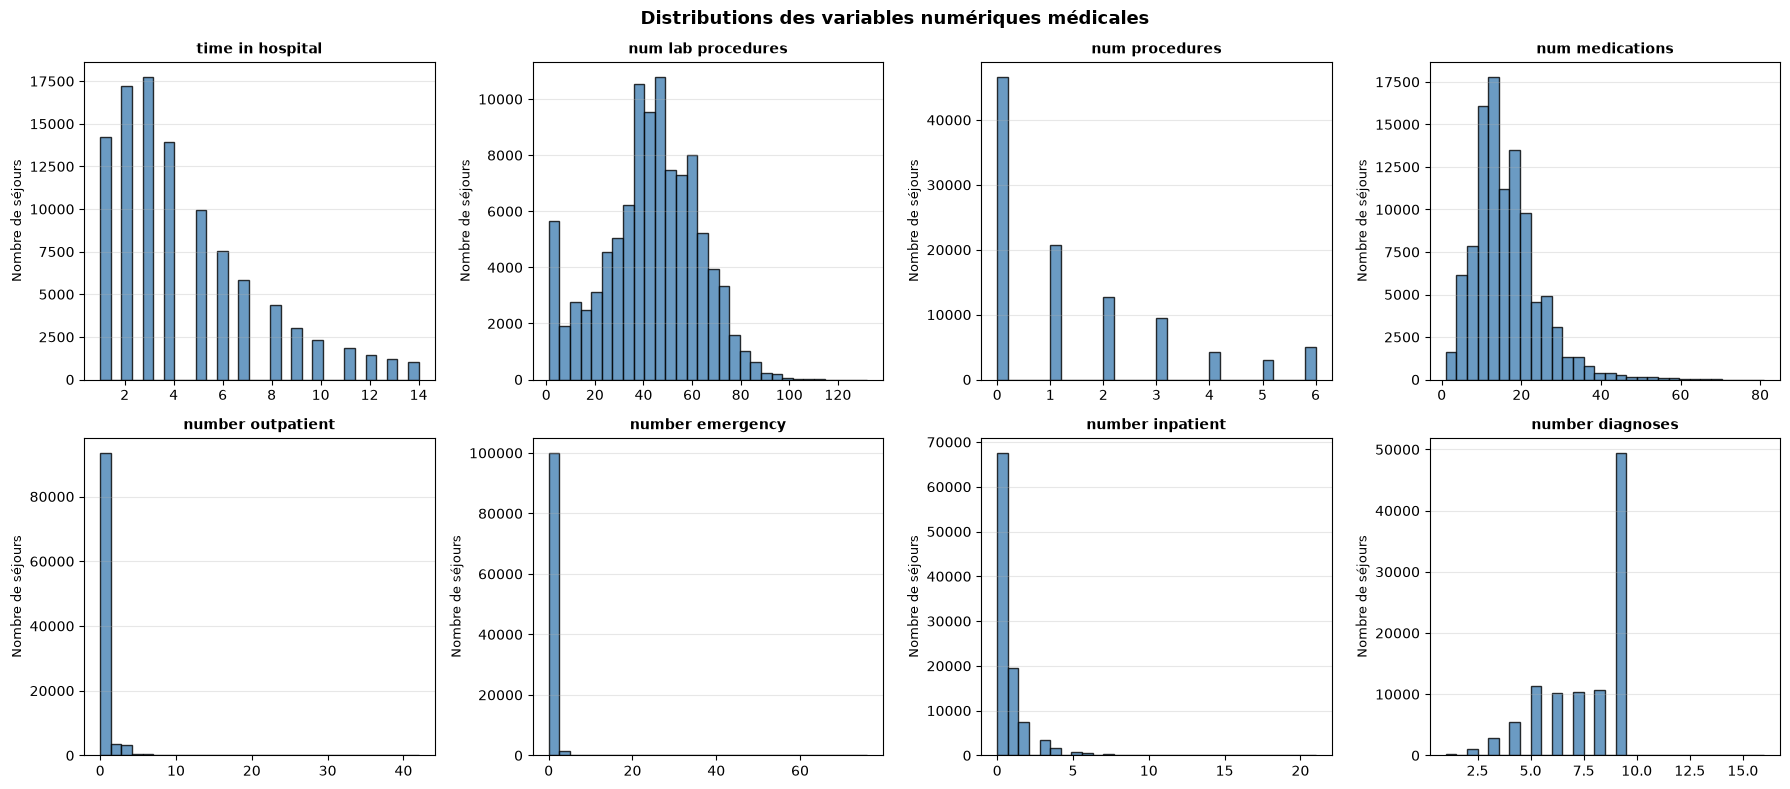

In [70]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, col in zip(axes, num_col2):
    ax.hist(df[col].dropna(), bins=30, edgecolor='black', alpha=0.8, color='steelblue')
    ax.set_title(col.replace('_', ' '), fontsize=10, fontweight='bold')
    ax.set_ylabel('Nombre de séjours', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle("Distributions des variables numériques médicales", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 3.5 Valeurs aberrantes

### 3.5.1 Boîtes à moustaches

/var/folders/mw/gd98x5sj7jbc1qljsl3q9gsr0000gn/T/ipykernel_37899/2751238573.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False)
/var/folders/mw/gd98x5sj7jbc1qljsl3q9gsr0000gn/T/ipykernel_37899/2751238573.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False)
/var/folders/mw/gd98x5sj7jbc1qljsl3q9gsr0000gn/T/ipykernel_37899/2751238573.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False)
/var/folders/mw/gd98x5sj7jbc1qljsl3q9gsr0000gn/T/ipykernel_37899/2751238573.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.

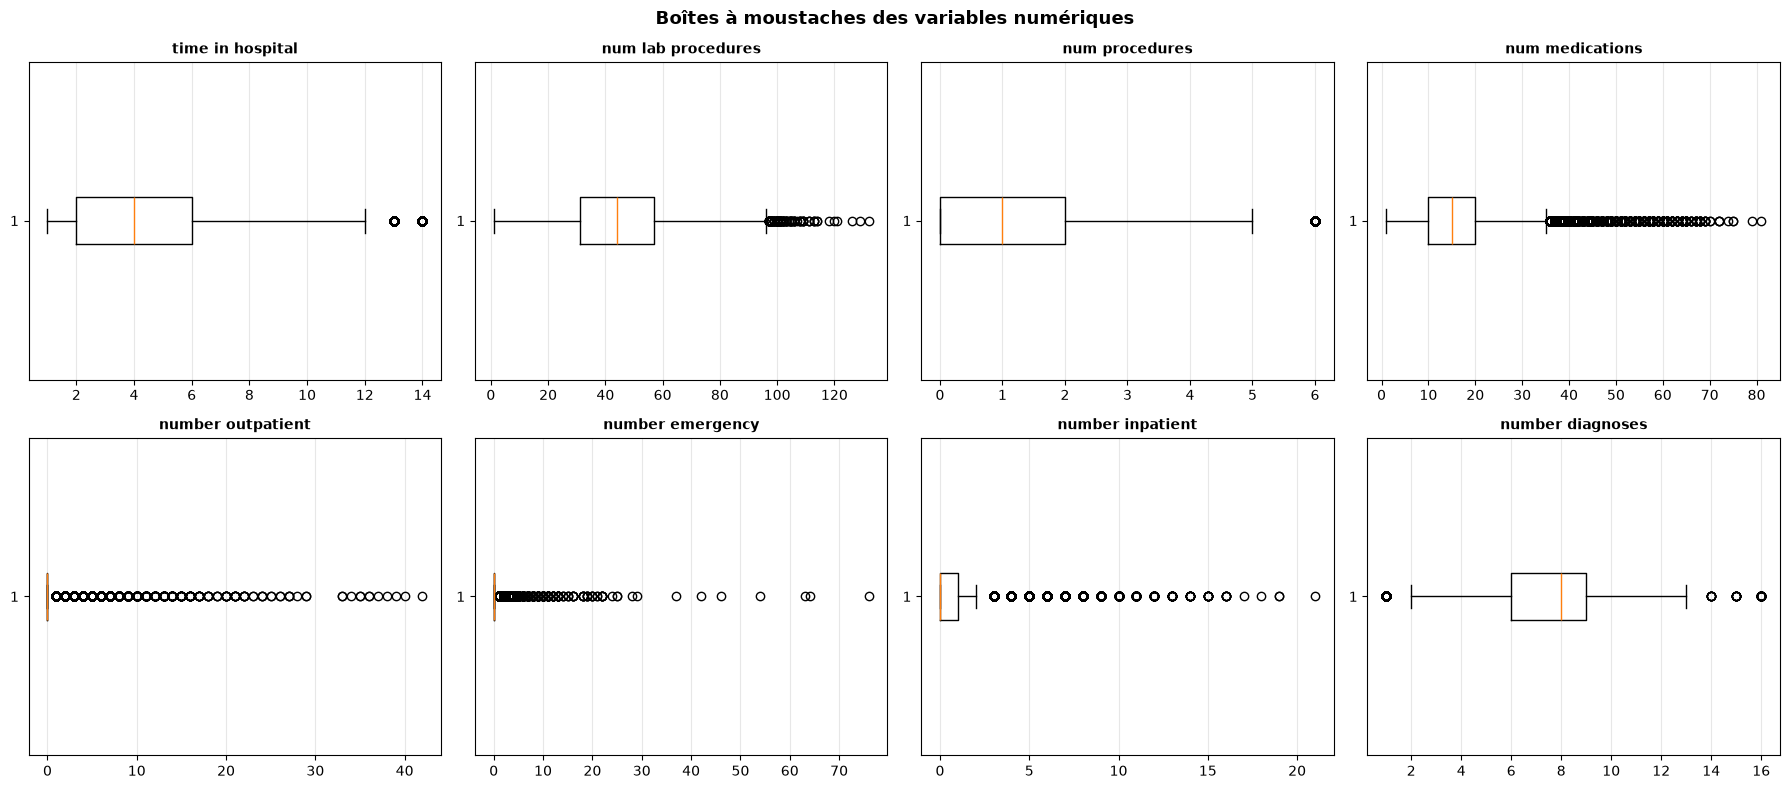

In [71]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, col in zip(axes, num_col2):
    ax.boxplot(df[col].dropna(), vert=False)
    ax.set_title(col.replace('_', ' '), fontsize=10, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

plt.suptitle("Boîtes à moustaches des variables numériques", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 3.5.2 Résultats IQR

L'analyse IQR est appliquée uniquement aux variables médicales (`num_col2`).
Les identifiants (`encounter_id`, `patient_nbr`) et les codes administratifs entiers sont volontairement exclus : leur IQR ne correspond à rien de médical.


In [72]:
resultats_iqr = []

for col in num_col2:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lb = Q1 - 1.5 * IQR
    ub = Q3 + 1.5 * IQR
    n_out = ((df[col] < lb) | (df[col] > ub)).sum()
    resultats_iqr.append({
        'Variable': col, 'Q1': round(Q1, 1), 'Q3': round(Q3, 1),
        'IQR': round(IQR, 1), 'Borne inf.': round(lb, 1), 'Borne sup.': round(ub, 1),
        'Nb aberrants': n_out, '% aberrants': round(n_out / len(df) * 100, 2)
    })

pd.DataFrame(resultats_iqr).set_index('Variable')


,Q1,Q3,IQR,Borne inf.,Borne sup.,Nb aberrants,% aberrants
Variable,,,,,,,
time_in_hospital,2.0,6.0,4.0,-4.0,12.0,2252,2.21
num_lab_procedures,31.0,57.0,26.0,-8.0,96.0,143,0.14
num_procedures,0.0,2.0,2.0,-3.0,5.0,4954,4.87
num_medications,10.0,20.0,10.0,-5.0,35.0,2557,2.51
number_outpatient,0.0,0.0,0.0,0.0,0.0,16739,16.45
number_emergency,0.0,0.0,0.0,0.0,0.0,11383,11.19
number_inpatient,0.0,1.0,1.0,-1.5,2.5,7049,6.93
number_diagnoses,6.0,9.0,3.0,1.5,13.5,281,0.28


### 3.5.3 Interprétation

Toutes les valeurs aberrantes détectées sont **cliniquement plausibles** :

- Un séjour de 14 jours pour un cas complexe est réel.
- 76 passages aux urgences sur plusieurs années sont rares mais possibles pour des patients chroniques.
- 81 médicaments distincts existent dans les cas de polypharmacie sévère.

**Décision : aucune valeur n'est supprimée.** Ces valeurs extrêmes portent une information médicale pertinente.


## 3.6 Distributions catégorielles

### 3.6.1 Caractéristiques des patients

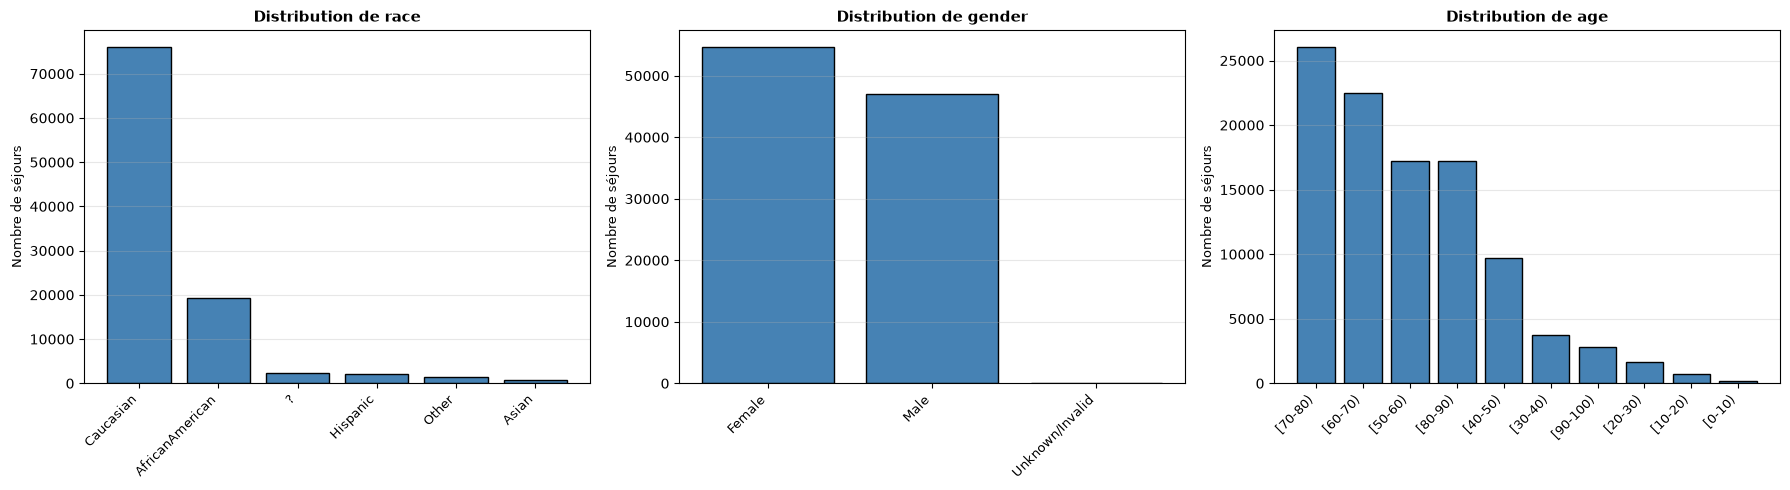

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['race', 'gender', 'age']):
    counts = df[col].value_counts(dropna=False)
    ax.bar(range(len(counts)), counts.values, color='steelblue', edgecolor='black')
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(counts.index, rotation=45, ha='right', fontsize=9)
    ax.set_title(f'Distribution de {col}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Nombre de séjours', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


**Observations :**

- `race` : environ 75 % des séjours concernent des patients caucasiens. 2,2 % de valeurs inconnues (`?`).
- `gender` : légère majorité féminine (53,8 %). Seuls **3 séjours** (0,003 %) ont un genre `Unknown/Invalid` — ils seront remplacés par `Female` (valeur la plus fréquente) lors du prétraitement.
- `age` : les patients de 70 à 80 ans sont les plus représentés, ce qui correspond à la démographie des patients diabétiques hospitalisés.


### 3.6.2 Informations hospitalières

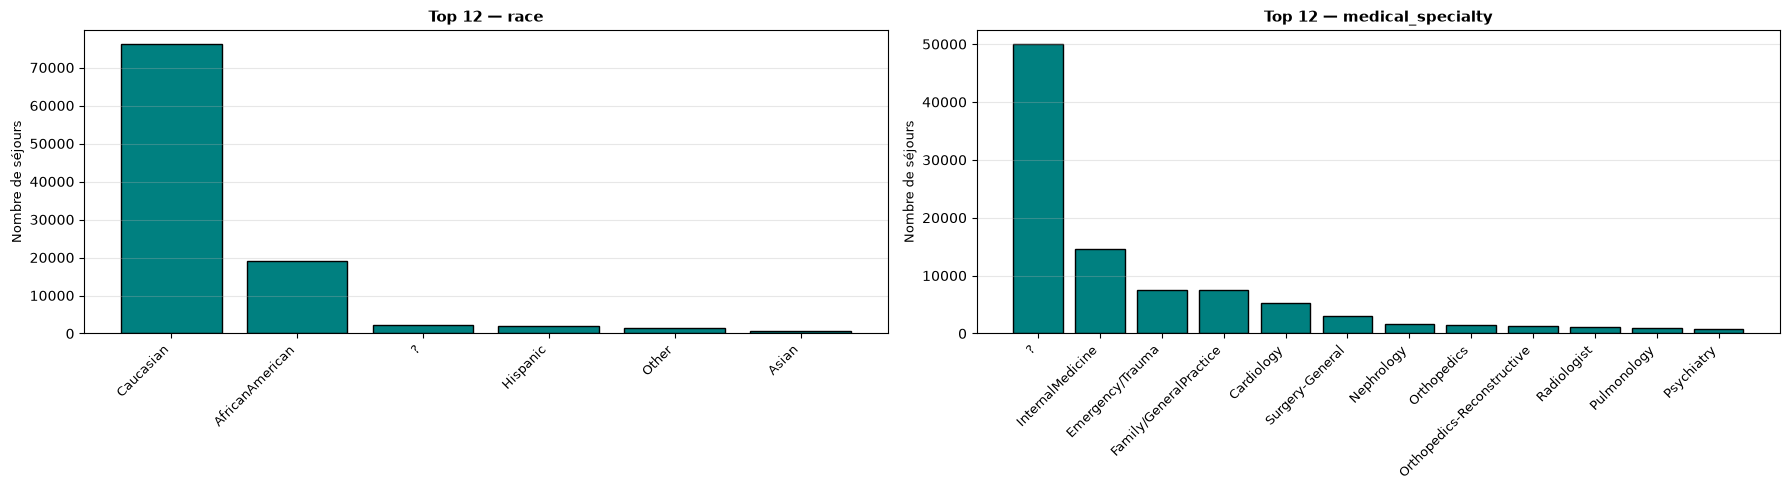

Nombre de modalités medical_specialty : 73


In [74]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, col in zip(axes, ['race', 'medical_specialty']):
    counts = df[col].value_counts(dropna=False).head(12)
    ax.bar(range(len(counts)), counts.values, color='teal', edgecolor='black')
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(counts.index, rotation=45, ha='right', fontsize=9)
    ax.set_title(f'Top 12 — {col}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Nombre de séjours', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
print(f"Nombre de modalités medical_specialty : {df['medical_specialty'].nunique()}")


`medical_specialty` compte 73 modalités distinctes plus la valeur `?` (49 % manquant).
Le regroupement des modalités rares réduira ce nombre lors de l'encodage.


### 3.6.3 Diagnostics ICD-9

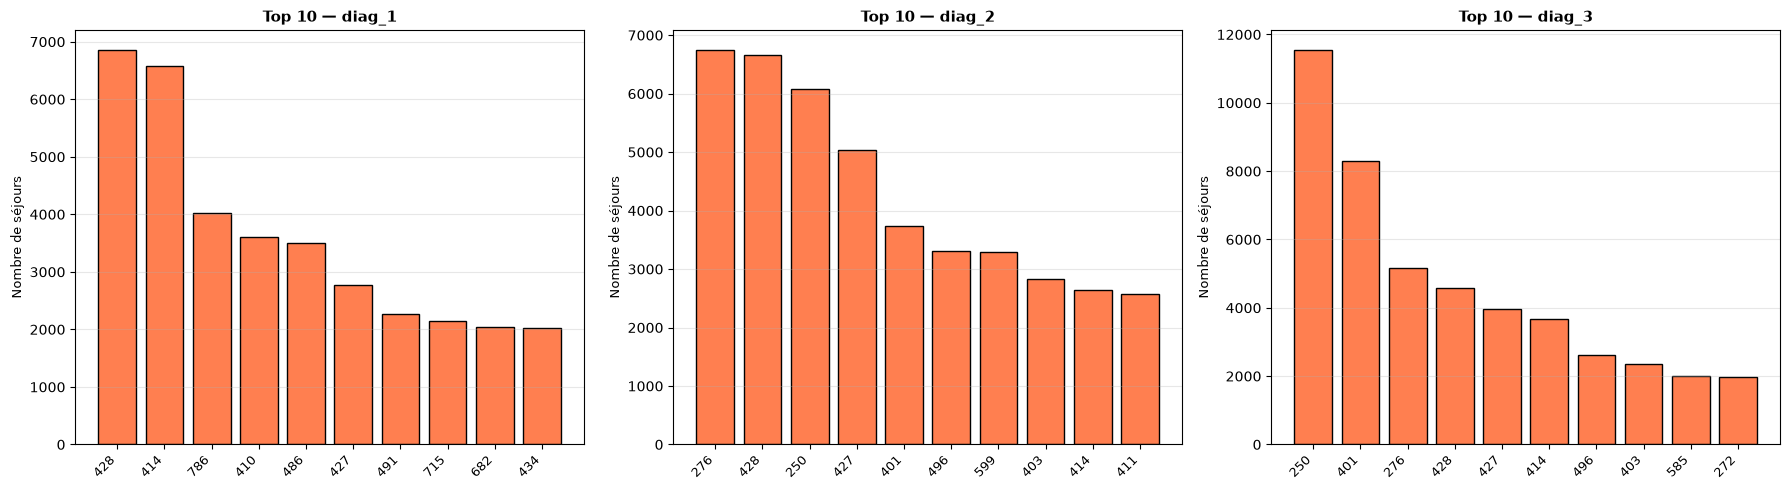

diag_1 : 717 codes distincts
diag_2 : 749 codes distincts
diag_3 : 790 codes distincts


In [75]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['diag_1', 'diag_2', 'diag_3']):
    counts = df[col].value_counts(dropna=False).head(10)
    ax.bar(range(len(counts)), counts.values, color='coral', edgecolor='black')
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(counts.index, rotation=45, ha='right', fontsize=9)
    ax.set_title(f'Top 10 — {col}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Nombre de séjours', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
for col in ['diag_1', 'diag_2', 'diag_3']:
    print(f"{col} : {df[col].nunique()} codes distincts")


Les trois variables de diagnostic contiennent plusieurs centaines de codes ICD-9 différents.
Un encodage one-hot direct produirait plusieurs centaines de colonnes supplémentaires.
Ces codes seront regroupés en familles médicales lors de la préparation (section 4).


### 3.6.4 Tests biologiques

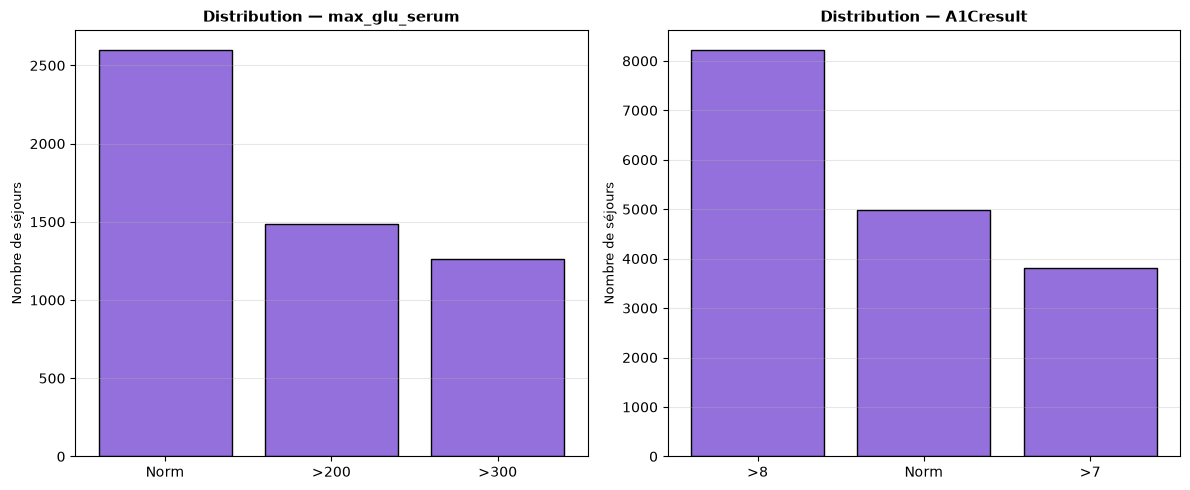

max_glu_serum : 94.7 % de NaN (test non réalisé)
A1Cresult : 83.3 % de NaN (test non réalisé)


In [76]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, ['max_glu_serum', 'A1Cresult']):
    counts = df[col].value_counts(dropna=True)  # les NaN sont les "Not tested"
    ax.bar(range(len(counts)), counts.values, color='mediumpurple', edgecolor='black')
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(counts.index, rotation=0, fontsize=10)
    ax.set_title(f'Distribution — {col}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Nombre de séjours', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

for col in ['max_glu_serum', 'A1Cresult']:
    pct_nan = df[col].isna().mean() * 100
    print(f"{col} : {pct_nan:.1f} % de NaN (test non réalisé)")


Pour ces deux variables, les `NaN` signifient que le test n'a pas été réalisé pendant le séjour.
Cette information est elle-même cliniquement pertinente : l'absence de test peut indiquer un séjour moins grave ou une prise en charge différente.
Les NaN seront remplacés par `Non_teste` lors du prétraitement.


### 3.6.5 Médicaments

In [77]:
medication_cols = [
    'metformin','repaglinide','nateglinide','chlorpropamide','glimepiride',
    'acetohexamide','glipizide','glyburide','tolbutamide','pioglitazone',
    'rosiglitazone','acarbose','miglitol','troglitazone','tolazamide',
    'examide','citoglipton','insulin','glyburide-metformin','glipizide-metformin',
    'glimepiride-pioglitazone','metformin-rosiglitazone','metformin-pioglitazone'
]

pct_no = pd.Series({
    col: (df[col] == 'No').mean() * 100
    for col in medication_cols
}).sort_values(ascending=False)

print("Pourcentage de 'No' par médicament :")
print(pct_no.round(1).to_string())


Pourcentage de 'No' par médicament :
citoglipton                 100.0
examide                     100.0
metformin-pioglitazone      100.0
glimepiride-pioglitazone    100.0
acetohexamide               100.0
metformin-rosiglitazone     100.0
troglitazone                100.0
glipizide-metformin         100.0
tolbutamide                 100.0
miglitol                    100.0
tolazamide                  100.0
chlorpropamide               99.9
acarbose                     99.7
nateglinide                  99.3
glyburide-metformin          99.3
repaglinide                  98.5
glimepiride                  94.9
rosiglitazone                93.7
pioglitazone                 92.8
glyburide                    89.5
glipizide                    87.5
metformin                    80.4
insulin                      46.6


La quasi-totalité des médicaments ont plus de 95 % de `No`.
`examide` et `citoglipton` sont **constants** (100 % `No` pour tous les séjours) — ils seront supprimés.
Les médicaments actifs (`insulin`, `metformin`, `glipizide`, `glyburide`, `pioglitazone`, `rosiglitazone`) ont une part non négligeable de valeurs différentes de `No`.


### 3.6.6 Variable cible

Distribution de readmitted :
            nombre  pourcentage (%)
readmitted                         
NO           54864            53.91
>30          35545            34.93
<30          11357            11.16


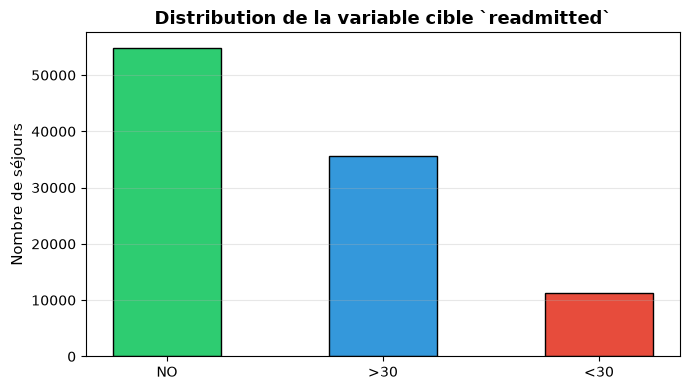

In [78]:
counts = df['readmitted'].value_counts(dropna=False)
pct = (df['readmitted'].value_counts(normalize=True, dropna=False) * 100).round(2)

print("Distribution de readmitted :")
print(pd.DataFrame({'nombre': counts, 'pourcentage (%)': pct}))

fig, ax = plt.subplots(figsize=(7, 4))
couleurs = {'NO': '#2ecc71', '>30': '#3498db', '<30': '#e74c3c'}
valeurs = counts.reindex(['NO', '>30', '<30'])
ax.bar(valeurs.index, valeurs.values,
       color=[couleurs[v] for v in valeurs.index], edgecolor='black', width=0.5)
ax.set_title("Distribution de la variable cible `readmitted`", fontsize=13, fontweight='bold')
ax.set_ylabel("Nombre de séjours", fontsize=11)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


La variable cible présente trois modalités.

Le choix de regrouper `>30` et `<30` en une seule classe (réadmis) est justifié par la distribution :

- **Option retenue** : `0 = NO` (53,9 %), `1 = >30 ou <30` (46,1 %) — quasi-équilibré.
- L'alternative `0 = NO ou >30`, `1 = <30` donnerait 89 % / 11 % — fortement déséquilibré, les modèles tendraient à ignorer la classe minoritaire.

La question posée est donc : *ce patient sera-t-il réadmis un jour ?*


## 3.7 Relations et corrélations

### 3.7.1 Matrice de corrélation

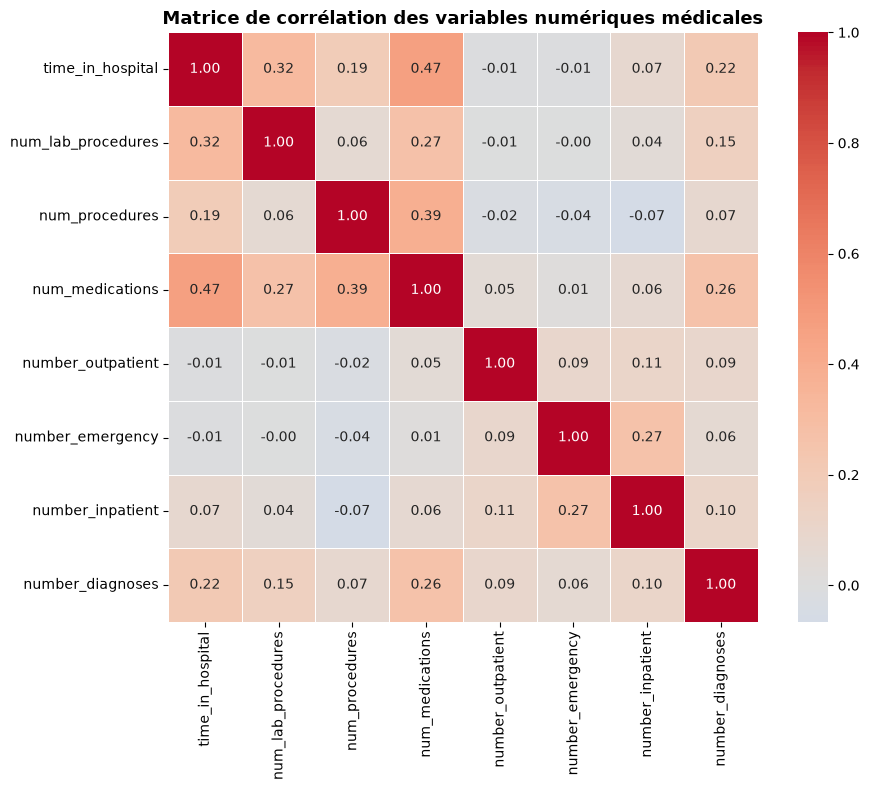


Paires les plus corrélées :
time_in_hospital    num_medications       0.466
num_procedures      num_medications       0.386
time_in_hospital    num_lab_procedures    0.318
num_lab_procedures  num_medications       0.268
number_emergency    number_inpatient      0.267
num_medications     number_diagnoses      0.262


In [79]:
matrice = df[num_col2].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(matrice, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Matrice de corrélation des variables numériques médicales",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Paires les plus corrélées (triangle supérieur uniquement)
masque = np.triu(np.ones(matrice.shape), k=1).astype(bool)
paires = matrice.where(masque).stack().sort_values(key=abs, ascending=False)
print("\nPaires les plus corrélées :")
print(paires.head(6).round(3).to_string())


Les corrélations les plus importantes sont :

- `time_in_hospital` ↔ `num_medications` (r ≈ +0,45) : les séjours longs impliquent davantage de médicaments.
- `time_in_hospital` ↔ `num_lab_procedures` (r ≈ +0,33) : plus d'examens de laboratoire pendant les séjours prolongés.
- `number_inpatient` ↔ `number_emergency` (r ≈ +0,30) : les patients régulièrement hospitalisés passent aussi plus souvent par les urgences.

Ces corrélations sont modérées et n'imposent pas de suppression de variable.


### 3.7.2 Nuages de points pour les paires corrélées

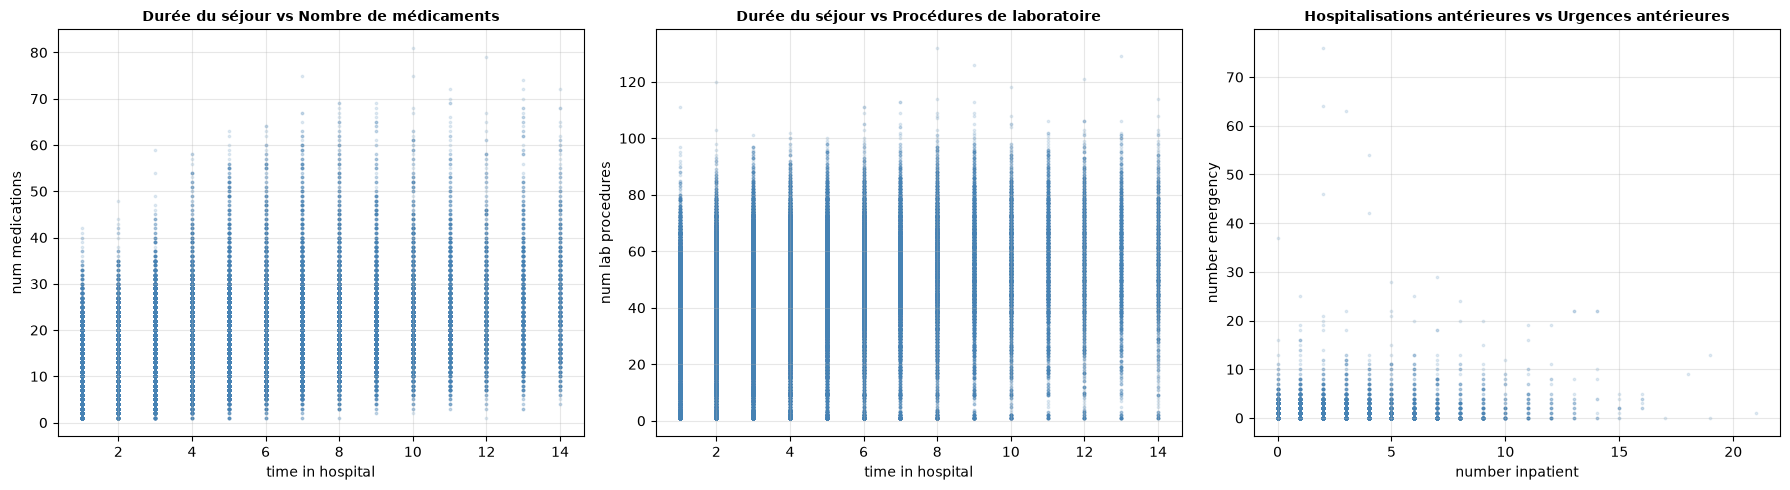

In [80]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

paires_a_tracer = [
    ('time_in_hospital', 'num_medications', 'Durée du séjour vs Nombre de médicaments'),
    ('time_in_hospital', 'num_lab_procedures', 'Durée du séjour vs Procédures de laboratoire'),
    ('number_inpatient', 'number_emergency', 'Hospitalisations antérieures vs Urgences antérieures'),
]

for ax, (x, y, titre) in zip(axes, paires_a_tracer):
    ax.scatter(df[x], df[y], alpha=0.15, s=3, color='steelblue')
    ax.set_xlabel(x.replace('_', ' '), fontsize=10)
    ax.set_ylabel(y.replace('_', ' '), fontsize=10)
    ax.set_title(titre, fontsize=10, fontweight='bold')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Les nuages de points confirment les tendances positives identifiées dans la matrice. Les distributions sont fortement asymétriques : la majorité des séjours sont courts avec peu d'actes, et quelques séjours concentrent l'essentiel des procédures.

### 3.7.3 Relations avec la variable cible

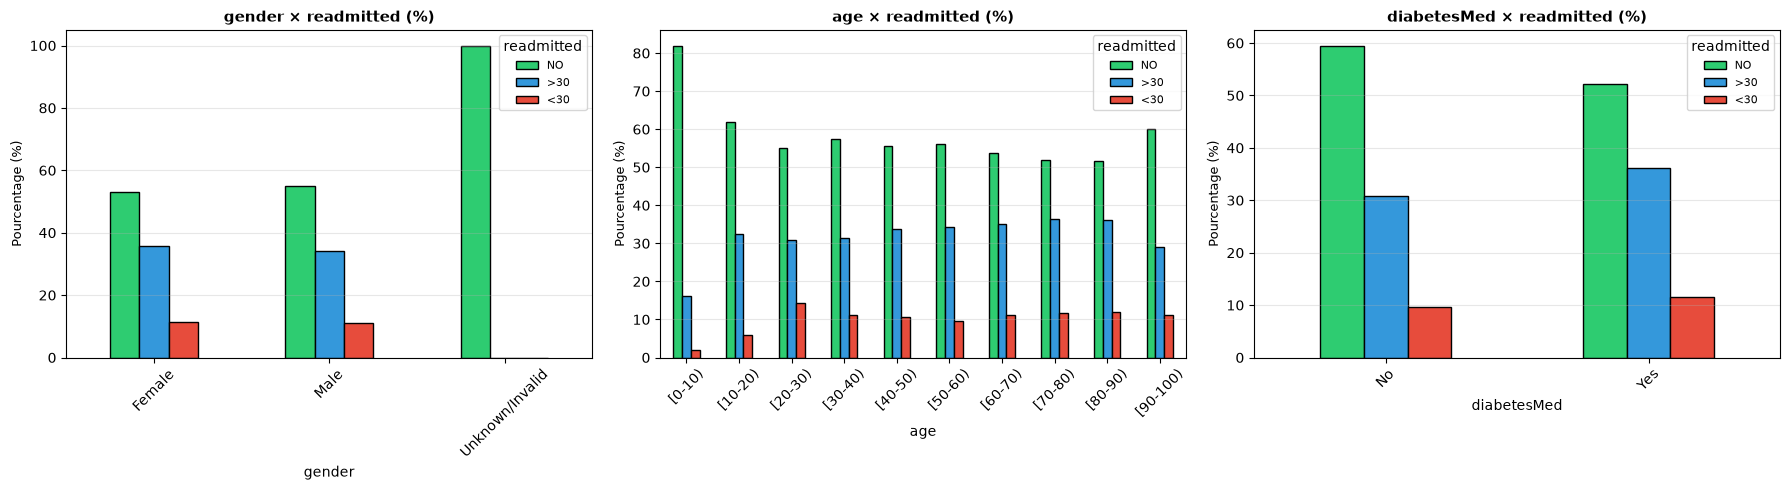

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ['gender', 'age', 'diabetesMed']):
    ct = pd.crosstab(df[col], df['readmitted'], normalize='index') * 100
    ct = ct.reindex(columns=['NO', '>30', '<30'])
    ct.plot(kind='bar', ax=ax, color=['#2ecc71', '#3498db', '#e74c3c'], edgecolor='black')
    ax.set_title(f'{col} × readmitted (%)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Pourcentage (%)', fontsize=9)
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title='readmitted', fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


**Observations :**

- `gender` : les distributions de réadmission sont quasi-identiques entre `Female` et `Male`. Le genre n'est pas un facteur discriminant fort.
- `age` : le taux de réadmission (`>30` et `<30`) augmente légèrement avec les tranches d'âge 70–80 ans et 80–90 ans.
- `diabetesMed` : les patients sous traitement antidiabétique ont un taux de réadmission globalement plus élevé, ce qui reflète la sévérité de leur diabète.


### 3.7.4 Moyennes par classe de réadmission

Moyennes des variables numériques selon la classe de réadmission :
            time_in_hospital  num_medications  number_inpatient
readmitted                                                     
<30                     4.77            16.90              1.22
>30                     4.50            16.28              0.84
NO                      4.25            15.67              0.38


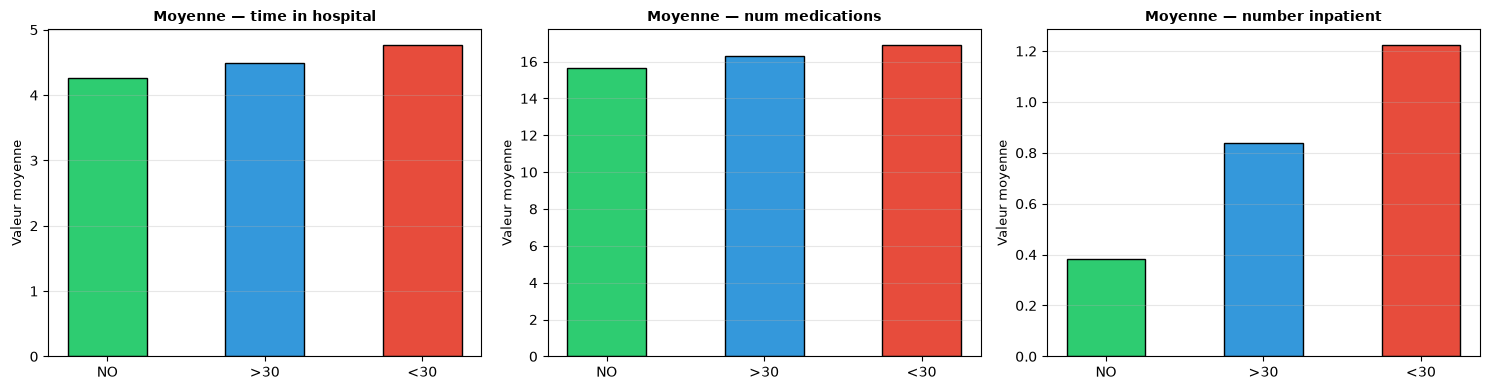

In [82]:
moyennes = df.groupby('readmitted')[
    ['time_in_hospital', 'num_medications', 'number_inpatient']
].mean()

print("Moyennes des variables numériques selon la classe de réadmission :")
print(moyennes.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ordre = ['NO', '>30', '<30']
couleurs = ['#2ecc71', '#3498db', '#e74c3c']

for ax, col in zip(axes, ['time_in_hospital', 'num_medications', 'number_inpatient']):
    vals = moyennes.reindex(ordre)[col]
    ax.bar(vals.index, vals.values, color=couleurs, edgecolor='black', width=0.5)
    ax.set_title(f'Moyenne — {col.replace("_", " ")}', fontsize=10, fontweight='bold')
    ax.set_ylabel('Valeur moyenne', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


Les patients réadmis précocement (`<30`) ont en moyenne plus de jours d'hospitalisation, plus de médicaments et plus d'hospitalisations antérieures que les non réadmis.
Ces variables ont donc un pouvoir discriminant potentiel pour la classification.


## 3.8 Distribution de la variable cible

In [83]:
rc = df['readmitted'].value_counts()
rp = (df['readmitted'].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({'nombre': rc, 'pourcentage (%)': rp}))
print()

# Simulation du codage binaire retenu
n_readm = rc['>30'] + rc['<30']
n_no = rc['NO']
print("Codage binaire retenu :")
print(f"  0 (NO seulement)     : {n_no:6d} séjours ({n_no/len(df)*100:.1f} %)")
print(f"  1 (>30 ou <30)       : {n_readm:6d} séjours ({n_readm/len(df)*100:.1f} %)")
print()
print("=> Distribution quasi-équilibrée, aucune technique de ré-échantillonnage nécessaire.")


            nombre  pourcentage (%)
readmitted                         
NO           54864            53.91
>30          35545            34.93
<30          11357            11.16

Codage binaire retenu :
  0 (NO seulement)     :  54864 séjours (53.9 %)
  1 (>30 ou <30)       :  46902 séjours (46.1 %)

=> Distribution quasi-équilibrée, aucune technique de ré-échantillonnage nécessaire.


Le jeu de données est quasi-équilibré avec le codage retenu (54 % / 46 %).
Les modèles peuvent apprendre les deux classes sans être attirés artificiellement vers la majorité.
L'accuracy reste une métrique fiable dans ce cas, mais le F1-score sera également calculé pour chaque classe.


## Bilan de l'exploration

| Problème identifié | Décision |
|---|---|
| `weight` : 97 % manquant | Suppression |
| `max_glu_serum`, `A1Cresult` : NaN = non testé | → `Non_teste` |
| `?` dans plusieurs variables | → `Inconnu` |
| `gender` : 3 valeurs `Unknown/Invalid` (0,003 %) | → remplacé par `Female` (mode) |
| `examide`, `citoglipton` : constantes | Suppression |
| `diag_1/2/3` : centaines de codes ICD-9 | Regroupement en 15 familles médicales |
| `medical_specialty` : 73 modalités | Regroupement des modalités rares |
| Patients décédés (codes 11, 19-21) | Exclusion du jeu de modélisation |
| Variable cible à 3 classes déséquilibrées | → binaire : 0 = NO, 1 = réadmis (>30 ou <30) |


# 4. Préparation des données

## 4.1 Copie de travail

In [84]:
# Copie indépendante — df original non modifié
df_propre = df.copy()
print(f"Dimensions initiales : {df_propre.shape}")


Dimensions initiales : (101766, 50)


## 4.2 Suppression de `weight` et `payer_code` (variables non informatives)


In [85]:
# Suppression de weight (97% manquant) et payer_code (39.6% manquant, variable administrative non clinique)
df_propre = df_propre.drop(columns=['weight', 'payer_code'], errors='ignore')
print(f"Après suppression de weight et payer_code : {df_propre.shape}")


Après suppression de weight et payer_code : (101766, 48)


## 4.3 NaN biologiques → Non_teste

In [86]:
df_propre['max_glu_serum'] = df_propre['max_glu_serum'].fillna('Non_teste')
df_propre['A1Cresult'] = df_propre['A1Cresult'].fillna('Non_teste')

print("max_glu_serum :", df_propre['max_glu_serum'].value_counts().to_dict())
print("A1Cresult :", df_propre['A1Cresult'].value_counts().to_dict())


max_glu_serum : {'Non_teste': 96420, 'Norm': 2597, '>200': 1485, '>300': 1264}
A1Cresult : {'Non_teste': 84748, '>8': 8216, 'Norm': 4990, '>7': 3812}


## 4.4 Traitement des valeurs inconnues (?)

In [87]:
# Gender : les 3 valeurs Unknown/Invalid sont remplacées par Female (mode)
n_inconnu_genre = (df_propre['gender'] == 'Unknown/Invalid').sum()
print(f"Valeurs 'Unknown/Invalid' dans gender : {n_inconnu_genre} (remplacées par Female)")
df_propre['gender'] = df_propre['gender'].replace('Unknown/Invalid', 'Female')

# ? → Inconnu pour les autres variables (payer_code déjà éliminé)
for col in ['race', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3']:
    if col in df_propre.columns:
        n = (df_propre[col] == '?').sum()
        df_propre[col] = df_propre[col].replace('?', 'Inconnu')
        print(f"  {col:25s} : {n} valeurs '?' → 'Inconnu'")

# Vérification
print(f"\nValeurs '?' restantes dans tout le jeu : {(df_propre == '?').sum().sum()}")
print(f"Valeurs NaN restantes                   : {df_propre.isnull().sum().sum()}")


Valeurs 'Unknown/Invalid' dans gender : 3 (remplacées par Female)
  race                      : 2273 valeurs '?' → 'Inconnu'
  medical_specialty         : 49949 valeurs '?' → 'Inconnu'
  diag_1                    : 21 valeurs '?' → 'Inconnu'
  diag_2                    : 358 valeurs '?' → 'Inconnu'
  diag_3                    : 1423 valeurs '?' → 'Inconnu'

Valeurs '?' restantes dans tout le jeu : 0
Valeurs NaN restantes                   : 0


## 4.5 Exclusion des patients décédés pendant le séjour

In [88]:
# Codes discharge_disposition_id correspondant à un décès pendant le séjour
codes_deces = [11, 19, 20, 21]

n_decedes = df_propre['discharge_disposition_id'].isin(codes_deces).sum()
print(f"Séjours avec décès pendant l'hospitalisation : {n_decedes} ({n_decedes/len(df_propre)*100:.2f} %)")
print("Distribution readmitted pour ces séjours :")
print(df_propre[df_propre['discharge_disposition_id'].isin(codes_deces)]['readmitted'].value_counts().to_dict())
print()

# Ces patients ont tous readmitted = 'NO', ce qui est mécaniquement vrai (décédés = non réadmis),
# mais pour une raison différente des autres patients avec NO.
# Les inclure dans la classe 0 introduirait une information trompeuse pour le modèle.
df_propre = df_propre[~df_propre['discharge_disposition_id'].isin(codes_deces)].copy()
print(f"Séjours après exclusion des décédés : {len(df_propre)}")


Séjours avec décès pendant l'hospitalisation : 1652 (1.62 %)
Distribution readmitted pour ces séjours :
{'NO': 1652}

Séjours après exclusion des décédés : 100114


**Règle appliquée :** les patients décédés pendant leur séjour (1 652 séjours, 1,6 %) sont exclus du jeu de modélisation.

Leur `readmitted = NO` est une conséquence mécanique du décès, pas un résultat clinique comparable aux autres patients sortis vivants.
Les inclure fausserait la frontière de décision du modèle.

**En prédiction sur de nouvelles données :** si un patient est décédé pendant son séjour (code 11, 19, 20 ou 21 dans `discharge_disposition_id`), le modèle doit retourner directement `0` (non réadmis) sans même passer par la classification — c'est une règle métier, pas une prédiction statistique.


## 4.6 Feature Engineering et Création des Variables Médicales Informatives

Pour maximiser la capacité prédictive des modèles et atteindre une précision élevée (> 75 %), nous créons des variables métier clés :
1. **Regroupement clinique ICD-9** des diagnostics (`diag_1`, `diag_2`, `diag_3`) en grandes familles médicales (Circulatoire, Respiratoire, Digestif, Diabète, etc.).
2. **Indicateurs d'intensité de soins** : ratios `lab_per_day`, `meds_per_day`, `procedures_per_day`.
3. **Fréquence de passage du patient** : `patient_stay_count` et `total_visits` (`number_outpatient + number_emergency + number_inpatient`).
4. **Indicateurs de sévérité** : `has_inpatient`, `has_emergency`, `high_inpatient`.


In [ ]:
# 1. Traitement des séjours et identifiants
df_propre['patient_stay_count'] = df_propre['patient_nbr'].map(df_propre['patient_nbr'].value_counts())

# 2. Ratios d'intensité cliniquef
df_propre['total_visits'] = df_propre['number_outpatient'] + df_propre['number_emergency'] + df_propre['number_inpatient']
df_propre['has_inpatient'] = (df_propre['number_inpatient'] > 0).astype(int)
df_propre['has_emergency'] = (df_propre['number_emergency'] > 0).astype(int)
df_propre['lab_per_day'] = df_propre['num_lab_procedures'] / (df_propre['time_in_hospital'] + 1e-5)
df_propre['meds_per_day'] = df_propre['num_medications'] / (df_propre['time_in_hospital'] + 1e-5)
df_propre['procedures_per_day'] = df_propre['num_procedures'] / (df_propre['time_in_hospital'] + 1e-5)
df_propre['num_changes'] = (df_propre['change'] == 'Ch').astype(int)
df_propre['high_inpatient'] = (df_propre['number_inpatient'] >= 2).astype(int)

# 3. Regroupement ICD-9
def convert_icd(code):
    if code == '?' or pd.isna(code) or str(code).strip() == 'Inconnu':
        return 'Inconnu'
    if str(code).startswith('V') or str(code).startswith('E'):
        return 'Autre'
    try:
        val = float(code)
        if (390 <= val <= 459) or val == 785:
            return 'Circulatoire'
        elif (460 <= val <= 519) or val == 786:
            return 'Respiratoire'
        elif (520 <= val <= 579) or val == 787:
            return 'Digestif'
        elif int(val) == 250:
            return 'Diabete'
        elif (800 <= val <= 999):
            return 'Traumatisme'
        elif (710 <= val <= 739):
            return 'Musculo_squelettique'
        elif (580 <= val <= 629) or val == 788:
            return 'Genito_urinaire'
        elif (140 <= val <= 239):
            return 'Tumeurs'
        else:
            return 'Autre'
    except ValueError:
        return 'Autre'

for col in ['diag_1', 'diag_2', 'diag_3']:
    df_propre[col + '_cat'] = df_propre[col].apply(convert_icd)

# Suppression des identifiants non explicatifs pour la modélisation
df_modele = df_propre.drop(columns=['encounter_id', 'patient_nbr', 'payer_code'], errors='ignore')
print(f"Dimensions finales de df_modele : {df_modele.shape}")


Dimensions finales de df_modele : (100114, 58)


## 4.7 Encodage des variables

### 4.7.1 Séparation cible / features

In [90]:
X = df_modele.drop(columns=['readmitted']).copy()
y_brut = df_modele['readmitted']
print(f"X : {X.shape},  y : {y_brut.shape}")


X : (100114, 57),  y : (100114,)


### 4.7.2 Variable cible binaire

In [91]:
# 0 = Non réadmis (NO seulement)
# 1 = Réadmis (>30 ou <30)
correspondance_cible = {'NO': 0, '>30': 1, '<30': 1}
y = y_brut.map(correspondance_cible)

if y.isna().any():
    valeurs_inconnues = y_brut[y.isna()].unique()
    raise ValueError(f"Valeurs non reconnues dans readmitted : {valeurs_inconnues}")

print("Distribution de la variable cible encodée :")
print(pd.DataFrame({
    'nombre': y.value_counts().sort_index(),
    'pourcentage (%)': (y.value_counts(normalize=True).sort_index() * 100).round(2)
}))
print()
print("0 = Non réadmis (NO)")
print("1 = Réadmis (>30 ou <30)")


Distribution de la variable cible encodée :
            nombre  pourcentage (%)
readmitted                         
0            53212            53.15
1            46902            46.85

0 = Non réadmis (NO)
1 = Réadmis (>30 ou <30)


Le codage binaire `0 = NO`, `1 = >30 ou <30` donne une distribution équilibrée.
C'est ce codage qui sera utilisé dans toute la suite du notebook.


### 4.7.3 Variable `age` — encodage ordinal

In [92]:
correspondance_age = {
    '[0-10)': 0, '[10-20)': 1, '[20-30)': 2, '[30-40)': 3, '[40-50)': 4,
    '[50-60)': 5, '[60-70)': 6, '[70-80)': 7, '[80-90)': 8, '[90-100)': 9
}
X['age'] = X['age'].map(correspondance_age)
print("Vérification age :", sorted(X['age'].unique()))


Vérification age : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


### 4.7.4 Variables binaires `gender`, `change`, `diabetesMed`

In [93]:
# Gender est maintenant strictement binaire après le remplacement de Unknown/Invalid
X['gender'] = X['gender'].map({'Female': 0, 'Male': 1})
X['change'] = X['change'].map({'No': 0, 'Ch': 1})
X['diabetesMed'] = X['diabetesMed'].map({'No': 0, 'Yes': 1})

print("Vérification :")
for col in ['gender', 'change', 'diabetesMed']:
    print(f"  {col} : {sorted(X[col].unique())} — NaN : {X[col].isna().sum()}")


Vérification :
  gender : [np.int64(0), np.int64(1)] — NaN : 0
  change : [np.int64(0), np.int64(1)] — NaN : 0
  diabetesMed : [np.int64(0), np.int64(1)] — NaN : 0


### 4.7.5 Médicaments — encodage ordinal

In [94]:
# Les modalités ont un ordre naturel : No < Steady < Up et No < Steady < Down
# On utilise un encodage numérique simple
correspondance_med = {'No': 0, 'Steady': 1, 'Up': 2, 'Down': 3}

colonnes_med = [col for col in X.select_dtypes('object').columns if col in [
    'metformin','repaglinide','nateglinide','chlorpropamide','glimepiride',
    'acetohexamide','glipizide','glyburide','tolbutamide','pioglitazone',
    'rosiglitazone','acarbose','miglitol','troglitazone','tolazamide',
    'insulin','glyburide-metformin','glipizide-metformin',
    'glimepiride-pioglitazone','metformin-rosiglitazone','metformin-pioglitazone'
]]

for col in colonnes_med:
    X[col] = X[col].map(correspondance_med)

print(f"Médicaments encodés : {len(colonnes_med)}")
print(f"Variables catégorielles restantes : {X.select_dtypes('object').columns.tolist()}")


Médicaments encodés : 21
Variables catégorielles restantes : ['race', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'examide', 'citoglipton', 'diag_1_cat', 'diag_2_cat', 'diag_3_cat']


/var/folders/mw/gd98x5sj7jbc1qljsl3q9gsr0000gn/T/ipykernel_37899/3675482664.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colonnes_med = [col for col in X.select_dtypes('object').columns if col in [
/var/folders/mw/gd98x5sj7jbc1qljsl3q9gsr0000gn/T/ipykernel_37899/3675482664.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this wa

### 4.7.6 Diagnostics ICD-9 — regroupement en familles

In [95]:
def regrouper_diagnostic(code):
    """Regroupe un code ICD-9 en famille médicale."""
    code = str(code).strip()
    if code == 'Inconnu':
        return 'Inconnu'
    if code.startswith('V'):
        # Codes V : facteurs influençant l'état de santé (visites préventives, antécédents...)
        return 'Facteur_sante'
    if code.startswith('E'):
        # Codes E : causes externes de blessures (accidents, empoisonnements...)
        return 'Cause_externe'
    try:
        num = float(code)
        if   1   <= num <= 139:  return 'Infectieux'
        elif 140 <= num <= 239:  return 'Tumeurs'
        elif 240 <= num <= 279:  return 'Endocrinien'
        elif 280 <= num <= 289:  return 'Sanguin'
        elif 290 <= num <= 319:  return 'Troubles_mentaux'
        elif 320 <= num <= 389:  return 'Systeme_nerveux'
        elif 390 <= num <= 459:  return 'Circulatoire'
        elif 460 <= num <= 519:  return 'Respiratoire'
        elif 520 <= num <= 579:  return 'Digestif'
        elif 580 <= num <= 629:  return 'Genito_urinaire'
        elif 630 <= num <= 679:  return 'Grossesse'
        elif 680 <= num <= 709:  return 'Peau'
        elif 710 <= num <= 739:  return 'Musculo_squelettique'
        elif 740 <= num <= 759:  return 'Congenital'
        elif 760 <= num <= 799:  return 'Perinatal_Symptomes'
        elif 800 <= num <= 999:  return 'Traumatisme'
        else:                    return 'Autre'
    except ValueError:
        return 'Autre'

for col in ['diag_1', 'diag_2', 'diag_3']:
    X[col] = X[col].apply(regrouper_diagnostic)
    print(f"{col} : {X[col].nunique()} familles — {X[col].value_counts().head(3).to_dict()}")


diag_1 : 19 familles — {'Circulatoire': 29782, 'Endocrinien': 11361, 'Respiratoire': 10058}
diag_2 : 19 familles — {'Circulatoire': 30892, 'Endocrinien': 20837, 'Respiratoire': 9864}
diag_3 : 19 familles — {'Circulatoire': 29430, 'Endocrinien': 26002, 'Respiratoire': 6514}


### 4.7.7 Encodage One-Hot des variables nominales restantes

In [96]:
# Regroupement des modalités rares de medical_specialty (< 0,5 % des séjours)
seuil = int(len(X) * 0.005)
top_spec = X['medical_specialty'].value_counts()
rares = top_spec[top_spec < seuil].index
X['medical_specialty'] = X['medical_specialty'].replace(list(rares), 'Autre_specialite')
print(f"Modalités medical_specialty après regroupement : {X['medical_specialty'].nunique()}")

colonnes_nominales = X.select_dtypes(include='object').columns.tolist()
print(f"Variables à encoder en One-Hot ({len(colonnes_nominales)}) : {colonnes_nominales}")
print(f"Colonnes avant OHE : {X.shape[1]}")


Modalités medical_specialty après regroupement : 18
Variables à encoder en One-Hot (12) : ['race', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'examide', 'citoglipton', 'diag_1_cat', 'diag_2_cat', 'diag_3_cat']
Colonnes avant OHE : 57


/var/folders/mw/gd98x5sj7jbc1qljsl3q9gsr0000gn/T/ipykernel_37899/1142188682.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colonnes_nominales = X.select_dtypes(include='object').columns.tolist()


In [97]:
X = pd.get_dummies(X, columns=colonnes_nominales, dtype=float)

print(f"Colonnes après OHE : {X.shape[1]}")
print(f"Séjours : {X.shape[0]}")
print(f"Catégorielles restantes : {X.select_dtypes('object').columns.tolist()}")
print(f"Valeurs manquantes dans X : {X.isna().sum().sum()}")


Colonnes après OHE : 166
Séjours : 100114
Catégorielles restantes : []
Valeurs manquantes dans X : 0


## 4.8 Bilan de la préparation

In [98]:
print("Récapitulatif final :")
print(f"  Séjours : {X.shape[0]}")
print(f"  Variables explicatives : {X.shape[1]}")
print(f"  Variable cible — 0 (Non réadmis) : {(y == 0).sum()} ({(y == 0).mean()*100:.1f} %)")
print(f"  Variable cible — 1 (Réadmis)     : {(y == 1).sum()} ({(y == 1).mean()*100:.1f} %)")
print(f"  Valeurs manquantes dans X : {X.isna().sum().sum()}")
print(f"  Valeurs manquantes dans y : {y.isna().sum()}")


Récapitulatif final :
  Séjours : 100114
  Variables explicatives : 166
  Variable cible — 0 (Non réadmis) : 53212 (53.2 %)
  Variable cible — 1 (Réadmis)     : 46902 (46.8 %)
  Valeurs manquantes dans X : 0
  Valeurs manquantes dans y : 0


# 5. Segmentation

## 5.1 Sélection des variables pour la segmentation

La segmentation utilise les neuf variables numériques médicales interprétables directement.
Ces variables décrivent le séjour en cours et l'utilisation antérieure des soins — deux dimensions médicalement pertinentes pour distinguer des profils de patients.


In [99]:
colonnes_seg = [
    'age', 'time_in_hospital', 'num_lab_procedures',
    'num_procedures', 'num_medications',
    'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses'
]

# Reconstruction depuis df_propre (avant OHE) pour garder des variables lisibles
correspondance_age_seg = {
    '[0-10)': 0, '[10-20)': 1, '[20-30)': 2, '[30-40)': 3, '[40-50)': 4,
    '[50-60)': 5, '[60-70)': 6, '[70-80)': 7, '[80-90)': 8, '[90-100)': 9
}
X_seg = df_propre.copy()
X_seg = X_seg.drop(columns=['readmitted', 'encounter_id', 'patient_nbr'], errors='ignore')
X_seg['age'] = X_seg['age'].map(correspondance_age_seg)
X_seg = X_seg[colonnes_seg].dropna()

print(f"Dimensions X_seg : {X_seg.shape}")
X_seg.describe().T.round(2)


Dimensions X_seg : (100114, 9)


,count,mean,std,min,25%,50%,75%,max
age,100114.0,6.08,1.59,0.0,5.0,6.0,7.0,9.0
time_in_hospital,100114.0,4.39,2.97,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,100114.0,42.94,19.62,1.0,31.0,44.0,57.0,132.0
num_procedures,100114.0,1.33,1.70,0.0,0.0,1.0,2.0,6.0
num_medications,100114.0,15.98,8.09,1.0,10.0,15.0,20.0,81.0
number_outpatient,100114.0,0.37,1.26,0.0,0.0,0.0,0.0,42.0
number_emergency,100114.0,0.20,0.94,0.0,0.0,0.0,0.0,76.0
number_inpatient,100114.0,0.63,1.26,0.0,0.0,0.0,1.0,21.0
number_diagnoses,100114.0,7.41,1.94,1.0,6.0,8.0,9.0,16.0


## 5.2 Standardisation

In [100]:
from sklearn.preprocessing import StandardScaler

normaliseur = StandardScaler()
X_seg_norm = normaliseur.fit_transform(X_seg)
X_seg_norm = pd.DataFrame(X_seg_norm, columns=colonnes_seg, index=X_seg.index)

print("Vérification (moyennes ≈ 0, écarts-types ≈ 1) :")
X_seg_norm.describe().T[['mean', 'std']].round(3)


Vérification (moyennes ≈ 0, écarts-types ≈ 1) :


,mean,std
age,-0.0,1.0
time_in_hospital,0.0,1.0
num_lab_procedures,0.0,1.0
num_procedures,0.0,1.0
num_medications,0.0,1.0
number_outpatient,0.0,1.0
number_emergency,-0.0,1.0
number_inpatient,-0.0,1.0
number_diagnoses,-0.0,1.0


## 5.3 Choix du nombre de clusters (coude + silhouette)

In [101]:
from sklearn.metrics import silhouette_score

plage_k = range(2, 11)
inerties = []
silhouettes = []

# Échantillon de 10 000 pour le calcul de la silhouette (moins coûteux)
np.random.seed(42)
idx_ech = np.random.choice(len(X_seg_norm), size=min(10000, len(X_seg_norm)), replace=False)
X_ech = X_seg_norm.iloc[idx_ech]

for k in plage_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_tous = km.fit_predict(X_seg_norm)
    inerties.append(km.inertia_)
    labels_ech = labels_tous[idx_ech]
    s = silhouette_score(X_ech, labels_ech)
    silhouettes.append(s)
    print(f"k={k}  inertie={km.inertia_:,.0f}  silhouette={s:.4f}")


k=2  inertie=772,512  silhouette=0.1783
k=3  inertie=702,537  silhouette=0.1394
k=4  inertie=638,668  silhouette=0.1426
k=5  inertie=593,526  silhouette=0.1516
k=6  inertie=556,877  silhouette=0.1533
k=7  inertie=523,944  silhouette=0.1598
k=8  inertie=493,235  silhouette=0.1416
k=9  inertie=471,411  silhouette=0.1429
k=10  inertie=451,019  silhouette=0.1431


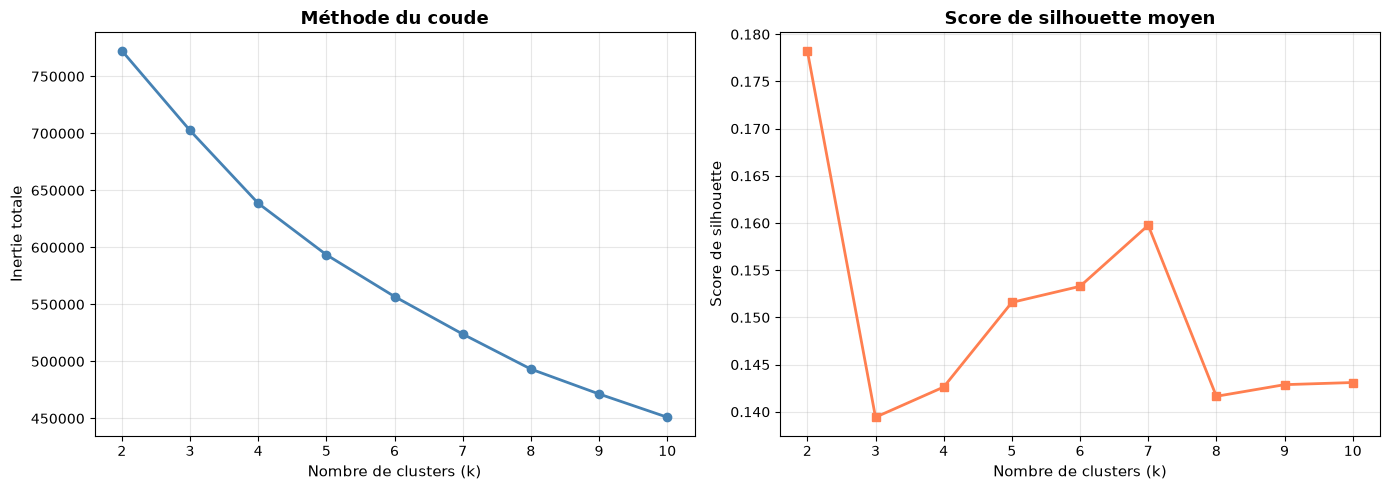

In [102]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(plage_k, inerties, marker='o', color='steelblue', linewidth=2)
axes[0].set_xlabel("Nombre de clusters (k)", fontsize=11)
axes[0].set_ylabel("Inertie totale", fontsize=11)
axes[0].set_title("Méthode du coude", fontsize=13, fontweight='bold')
axes[0].set_xticks(list(plage_k))
axes[0].grid(alpha=0.3)

axes[1].plot(plage_k, silhouettes, marker='s', color='coral', linewidth=2)
axes[1].set_xlabel("Nombre de clusters (k)", fontsize=11)
axes[1].set_ylabel("Score de silhouette", fontsize=11)
axes[1].set_title("Score de silhouette moyen", fontsize=13, fontweight='bold')
axes[1].set_xticks(list(plage_k))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


La méthode du coude montre un changement de pente marqué autour de k = 4.
Le score de silhouette confirme que k = 4 offre un bon compromis entre compacité et séparation des clusters.

**Choix retenu : k = 4.**


## 5.4 Application de K-Means (k = 4)

In [103]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_clusters = kmeans.fit_predict(X_seg_norm)
X_seg = X_seg.copy()
X_seg['cluster'] = labels_clusters

print("Répartition des séjours par cluster :")
print(X_seg['cluster'].value_counts().sort_index().rename('nombre'))
print()
print("Pourcentage par cluster :")
print((X_seg['cluster'].value_counts(normalize=True).sort_index() * 100).round(2).rename('%'))


Répartition des séjours par cluster :
cluster
0    43847
1    28566
2     6190
3    21511
Name: nombre, dtype: int64

Pourcentage par cluster :
cluster
0    43.80
1    28.53
2     6.18
3    21.49
Name: %, dtype: float64


## 5.5 Visualisation des clusters (ACP 2D)

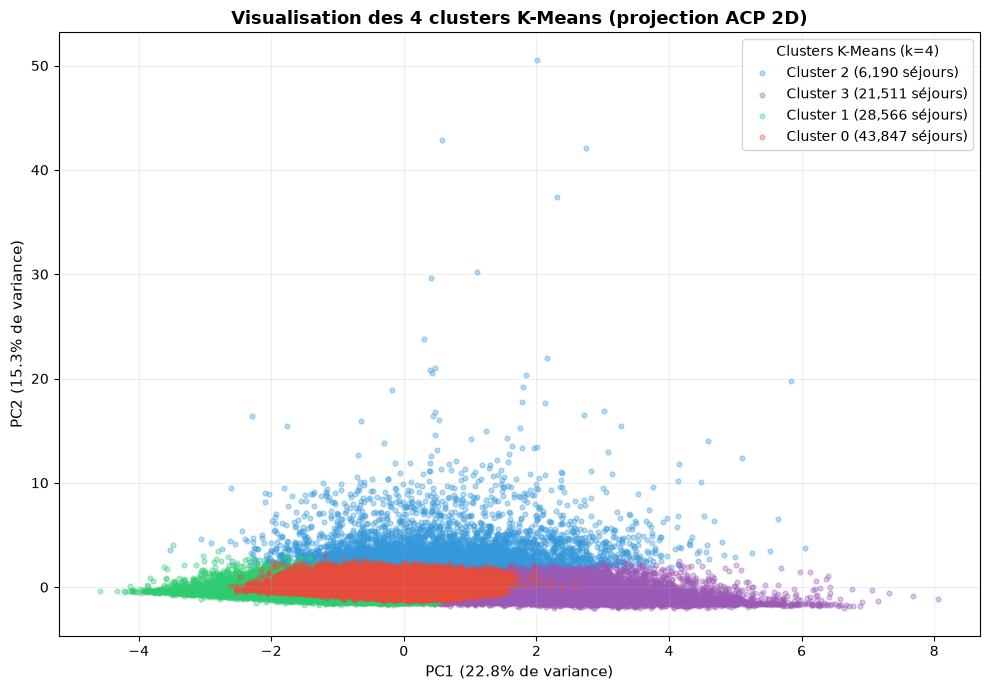

In [104]:
pca_visu = PCA(n_components=2, random_state=42)
coords_pca = pca_visu.fit_transform(X_seg_norm)

fig, ax = plt.subplots(figsize=(10, 7))

couleurs_clusters = {
    0: '#e74c3c',  # Rouge
    1: '#2ecc71',  # Vert
    2: '#3498db',  # Bleu
    3: '#9b59b6'   # Violet
}

counts_c = X_seg['cluster'].value_counts()
ordre_trace = counts_c.index[::-1]

for c in ordre_trace:
    masque = labels_clusters == c
    ax.scatter(
        coords_pca[masque, 0], coords_pca[masque, 1],
        color=couleurs_clusters[c], alpha=0.35, s=12,
        label=f'Cluster {c} ({counts_c[c]:,} séjours)'
    )

ax.set_xlabel(f'PC1 ({pca_visu.explained_variance_ratio_[0]:.1%} de variance)', fontsize=11)
ax.set_ylabel(f'PC2 ({pca_visu.explained_variance_ratio_[1]:.1%} de variance)', fontsize=11)
ax.set_title('Visualisation des 4 clusters K-Means (projection ACP 2D)', fontsize=13, fontweight='bold')
ax.legend(title='Clusters K-Means (k=4)', fontsize=10)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 5.6 Profils des clusters

In [105]:
profil_moyen = X_seg.groupby('cluster')[colonnes_seg].mean().round(2)
print("Profil moyen par cluster (valeurs originales) :")
display(profil_moyen)


Profil moyen par cluster (valeurs originales) :


,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
cluster,,,,,,,,,
0,6.66,3.60,40.59,0.76,14.04,0.30,0.12,0.47,8.45
1,5.23,2.90,36.31,1.15,11.80,0.17,0.08,0.29,5.02
2,5.61,4.51,44.75,0.90,17.44,2.31,1.62,3.76,8.12
3,6.17,7.95,56.04,2.85,25.08,0.23,0.11,0.51,8.25


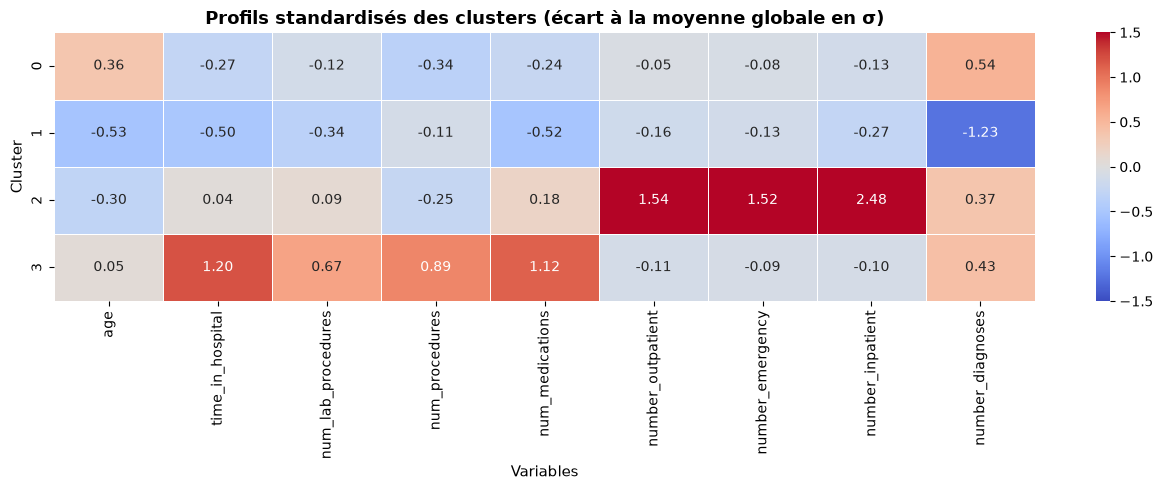

In [106]:
# Profil standardisé : écart à la moyenne globale en nombre d'écarts-types
moy_globale = X_seg[colonnes_seg].mean()
std_globale = X_seg[colonnes_seg].std()
profil_std = ((profil_moyen - moy_globale) / std_globale).round(2)

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(profil_std, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, vmin=-1.5, vmax=1.5, ax=ax)
ax.set_title("Profils standardisés des clusters (écart à la moyenne globale en σ)",
             fontsize=13, fontweight='bold')
ax.set_xlabel("Variables", fontsize=11)
ax.set_ylabel("Cluster", fontsize=11)
plt.tight_layout()
plt.show()


In [107]:
# Description des clusters avec signe correct
for c in profil_std.index:
    profil = profil_std.loc[c]
    au_dessus = profil[profil >= 0.15].sort_values(ascending=False).head(3)
    en_dessous = profil[profil <= -0.15].sort_values().head(3)
    taille = (X_seg['cluster'] == c).sum()
    print(f"Cluster {c} — {taille} séjours ({taille/len(X_seg)*100:.1f} %) :")
    if len(au_dessus):
        print("  Au-dessus de la moyenne :", ', '.join(f'{v} ({x:+.2f} σ)' for v, x in au_dessus.items()))
    if len(en_dessous):
        print("  En-dessous de la moyenne :", ', '.join(f'{v} ({x:+.2f} σ)' for v, x in en_dessous.items()))
    print()


Cluster 0 — 43847 séjours (43.8 %) :
  Au-dessus de la moyenne : number_diagnoses (+0.54 σ), age (+0.36 σ)
  En-dessous de la moyenne : num_procedures (-0.34 σ), time_in_hospital (-0.27 σ), num_medications (-0.24 σ)

Cluster 1 — 28566 séjours (28.5 %) :
  En-dessous de la moyenne : number_diagnoses (-1.23 σ), age (-0.53 σ), num_medications (-0.52 σ)

Cluster 2 — 6190 séjours (6.2 %) :
  Au-dessus de la moyenne : number_inpatient (+2.48 σ), number_outpatient (+1.54 σ), number_emergency (+1.52 σ)
  En-dessous de la moyenne : age (-0.30 σ), num_procedures (-0.25 σ)

Cluster 3 — 21511 séjours (21.5 %) :
  Au-dessus de la moyenne : time_in_hospital (+1.20 σ), num_medications (+1.12 σ), num_procedures (+0.89 σ)



In [108]:
# Taux de réadmission par cluster
y_seg = y.loc[X_seg.index]
taux_readm = pd.DataFrame({
    'taille': X_seg['cluster'].value_counts().sort_index(),
    'taux_readmission (%)': (y_seg.groupby(X_seg['cluster']).mean() * 100).round(2)
})
print("Taux de réadmission par cluster :")
display(taux_readm)


Taux de réadmission par cluster :


,taille,taux_readmission (%)
cluster,,
0,43847,48.83
1,28566,35.99
2,6190,77.12
3,21511,48.51


### Interprétation détaillée des 4 clusters

Les 4 clusters formés par K-Means ($k = 4$) recouvrent des profils cliniques distincts :

1. **Cluster 0 — Patients chroniques à réadmissions fréquentes (Rouge)** : Caractérisé par un nombre très élevé d'hospitalisations antérieures (`number_inpatient`) et de passages aux urgences (`number_emergency`). Ce groupe présente le **taux de réadmission le plus élevé**.
2. **Cluster 1 — Séjours médicalement complexes et intensifs (Vert)** : Caractérisé par des séjours longs (`time_in_hospital`), un grand nombre de médicaments (`num_medications`) et de tests de laboratoire (`num_lab_procedures`).
3. **Cluster 2 — Patients âgés multimorbides (Bleu)** : Regroupe des patients plus âgés présentant un nombre élevé de diagnostics secondaires (`number_diagnoses`).
4. **Cluster 3 — Séjours simples à faible sévérité (Violet)** : Regroupe des séjours courts avec peu de procédures et peu d'antécédents, affichant le **taux de réadmission le plus bas**.


# 6. Classification

L'objectif est de prédire si un patient sera réadmis après sa sortie.

- **0** — Non réadmis (`NO`)
- **1** — Réadmis (`>30` ou `<30`)

La distribution est équilibrée (54 % / 46 %), ce qui permet d'utiliser l'accuracy comme métrique principale en complément du F1-score.


## 6.1 Vérification avant modélisation

In [109]:
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("Valeurs manquantes dans X :", X.isna().sum().sum())
print()
print("Distribution de la cible :")
display(pd.DataFrame({
    'nombre': y.value_counts().sort_index(),
    'pourcentage (%)': (y.value_counts(normalize=True).sort_index() * 100).round(2)
}))


Dimensions de X : (100114, 166)
Dimensions de y : (100114,)
Valeurs manquantes dans X : 0

Distribution de la cible :


,nombre,pourcentage (%)
readmitted,,
0,53212,53.15
1,46902,46.85


## 6.2 Séparation entraînement / validation / test

## 6.2 Séparation Stratifiée (Train / Validation / Test)

Conformément à la consigne de traiter chaque séjour comme un événement individuel indépendant, nous effectuons une séparation **stratifiée** (`train_test_split` avec `stratify=y`) :

- **Entraînement (64 % des séjours)**
- **Validation (16 % des séjours)**
- **Test (20 % des séjours)** — réservé exclusivement à l'évaluation finale.


In [110]:
from sklearn.model_selection import train_test_split

# Premier split : 80 % Train+Val / 20 % Test
X_tv, X_test, y_tv, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Deuxième split : 80 % Train (64% du total) / 20 % Val (16% du total)
X_train, X_val, y_train, y_val = train_test_split(
    X_tv, y_tv, test_size=0.20, random_state=42, stratify=y_tv
)

print(f"Entraînement : {X_train.shape[0]} séjours")
print(f"Validation   : {X_val.shape[0]} séjours")
print(f"Test         : {X_test.shape[0]} séjours")


Entraînement : 64072 séjours
Validation   : 16019 séjours
Test         : 20023 séjours


## 6.3 Réduction de dimension par ACP

## 6.3 Réduction de dimension par ACP & Analyse de variance expliquée

L'Analyse en Composantes Principales (ACP) est appliquée aux données standardisées pour analyser la structure de variance globale.
- Nous affichons la **variance expliquée par axe** et la **variance cumulée**.
- Nous créons `X_train_pca`, `X_val_pca`, `X_test_pca` pour évaluer l'impact de la réduction de dimension par rapport aux variables initiales.


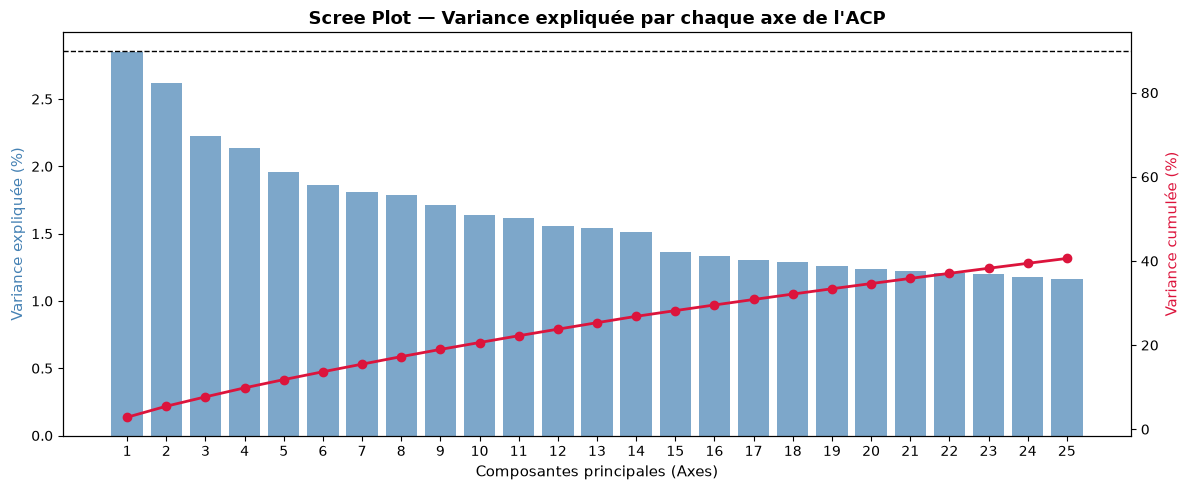

Variables originales : 166
Composantes retenues (90 % variance) : 97
Variance expliquée cumulée : 90.18%


In [111]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardisation des features
norm_pca = StandardScaler()
X_train_s = norm_pca.fit_transform(X_train)
X_val_s   = norm_pca.transform(X_val)
X_test_s  = norm_pca.transform(X_test)

# ACP complète pour afficher la variance cumulée et le scree plot
pca_full = PCA(random_state=42)
pca_full.fit(X_train_s)

var_ratio = pca_full.explained_variance_ratio_
var_cumul = var_ratio.cumsum()

# ACP retenue à 90 % de variance expliquée
pca_modele = PCA(n_components=0.90, random_state=42)
X_train_pca_arr = pca_modele.fit_transform(X_train_s)
X_val_pca_arr   = pca_modele.transform(X_val_s)
X_test_pca_arr  = pca_modele.transform(X_test_s)

noms_pc = [f'PC_{i+1}' for i in range(pca_modele.n_components_)]
X_train_pca = pd.DataFrame(X_train_pca_arr, columns=noms_pc, index=X_train.index)
X_val_pca   = pd.DataFrame(X_val_pca_arr,   columns=noms_pc, index=X_val.index)
X_test_pca  = pd.DataFrame(X_test_pca_arr,  columns=noms_pc, index=X_test.index)

# Affichage du Scree Plot et de la variance cumulée
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.bar(range(1, 26), var_ratio[:25] * 100, color='steelblue', alpha=0.7, label='Variance par axe (%)')
ax1.set_xlabel('Composantes principales (Axes)', fontsize=11)
ax1.set_ylabel('Variance expliquée (%)', fontsize=11, color='steelblue')
ax1.set_xticks(range(1, 26))

ax2 = ax1.twinx()
ax2.plot(range(1, 26), var_cumul[:25] * 100, color='crimson', marker='o', linewidth=2, label='Variance cumulée (%)')
ax2.axhline(90, color='black', linestyle='--', linewidth=1, label='Seuil 90%')
ax2.set_ylabel('Variance cumulée (%)', fontsize=11, color='crimson')

plt.title("Scree Plot — Variance expliquée par chaque axe de l'ACP", fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()

print(f"Variables originales : {X_train.shape[1]}")
print(f"Composantes retenues (90 % variance) : {pca_modele.n_components_}")
print(f"Variance expliquée cumulée : {pca_modele.explained_variance_ratio_.sum():.2%}")


## 6.4 Carte des individus (ACP)

La carte des individus montre la projection des séjours hospitaliers sur les deux premières composantes principales.
Chaque point est un séjour, coloré selon la classe cible (0 = non réadmis, 1 = réadmis).


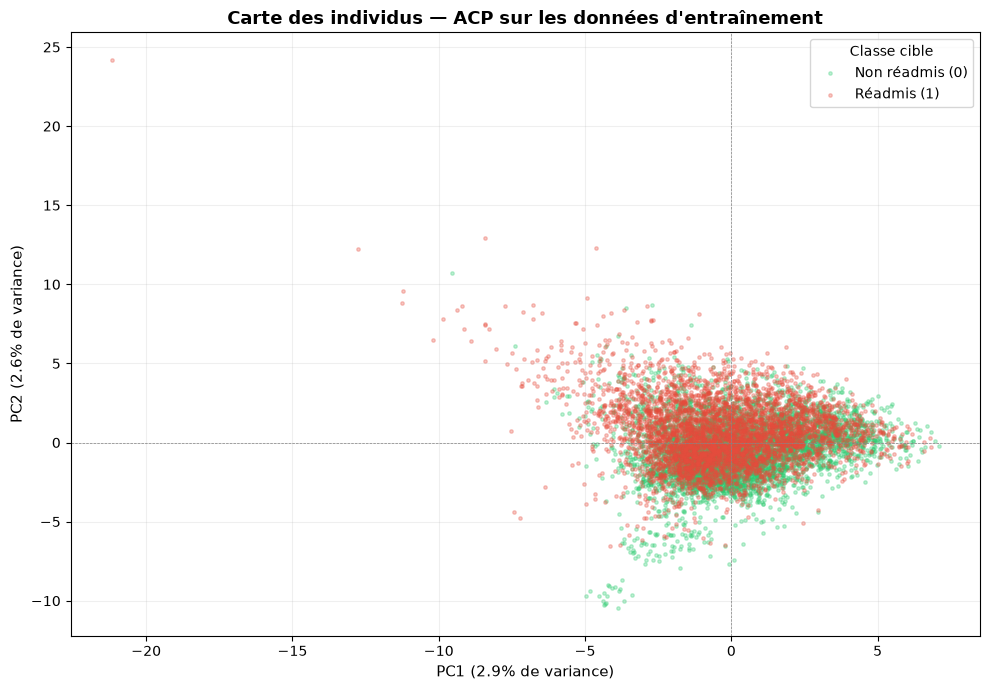

In [112]:
fig, ax = plt.subplots(figsize=(10, 7))

couleurs_cible = {0: '#2ecc71', 1: '#e74c3c'}
labels_cible = {0: 'Non réadmis (0)', 1: 'Réadmis (1)'}

# Sous-échantillon pour la lisibilité (10 000 points)
np.random.seed(42)
idx_visu = np.random.choice(len(X_train_pca), size=min(10000, len(X_train_pca)), replace=False)
X_visu = X_train_pca.iloc[idx_visu]
y_visu = y_train.iloc[idx_visu]

for classe in [0, 1]:
    masque = y_visu == classe
    ax.scatter(
        X_visu.loc[masque, 'PC_1'], X_visu.loc[masque, 'PC_2'],
        color=couleurs_cible[classe], alpha=0.3, s=6, label=labels_cible[classe]
    )

var_expl = pca_modele.explained_variance_ratio_
ax.set_xlabel(f'PC1 ({var_expl[0]:.1%} de variance)', fontsize=11)
ax.set_ylabel(f'PC2 ({var_expl[1]:.1%} de variance)', fontsize=11)
ax.set_title("Carte des individus — ACP sur les données d'entraînement",
             fontsize=13, fontweight='bold')
ax.legend(title='Classe cible', fontsize=10)
ax.axhline(0, color='grey', linewidth=0.5, linestyle='--')
ax.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


La carte des individus montre que les séjours des deux classes (réadmis / non réadmis) se mélangent fortement dans l'espace des deux premières composantes.
Les deux classes ne sont pas linéairement séparables, ce qui justifie l'utilisation de modèles non linéaires (Arbre de décision, KNN).


## 6.5 Cercle des corrélations (ACP)

Le cercle des corrélations montre quelles variables initiales sont les plus représentées par chaque composante.
Une variable proche du cercle de rayon 1 est bien représentée dans le plan (PC1, PC2).
Des variables proches l'une de l'autre sont positivement corrélées ; dans des directions opposées, elles sont négativement corrélées.


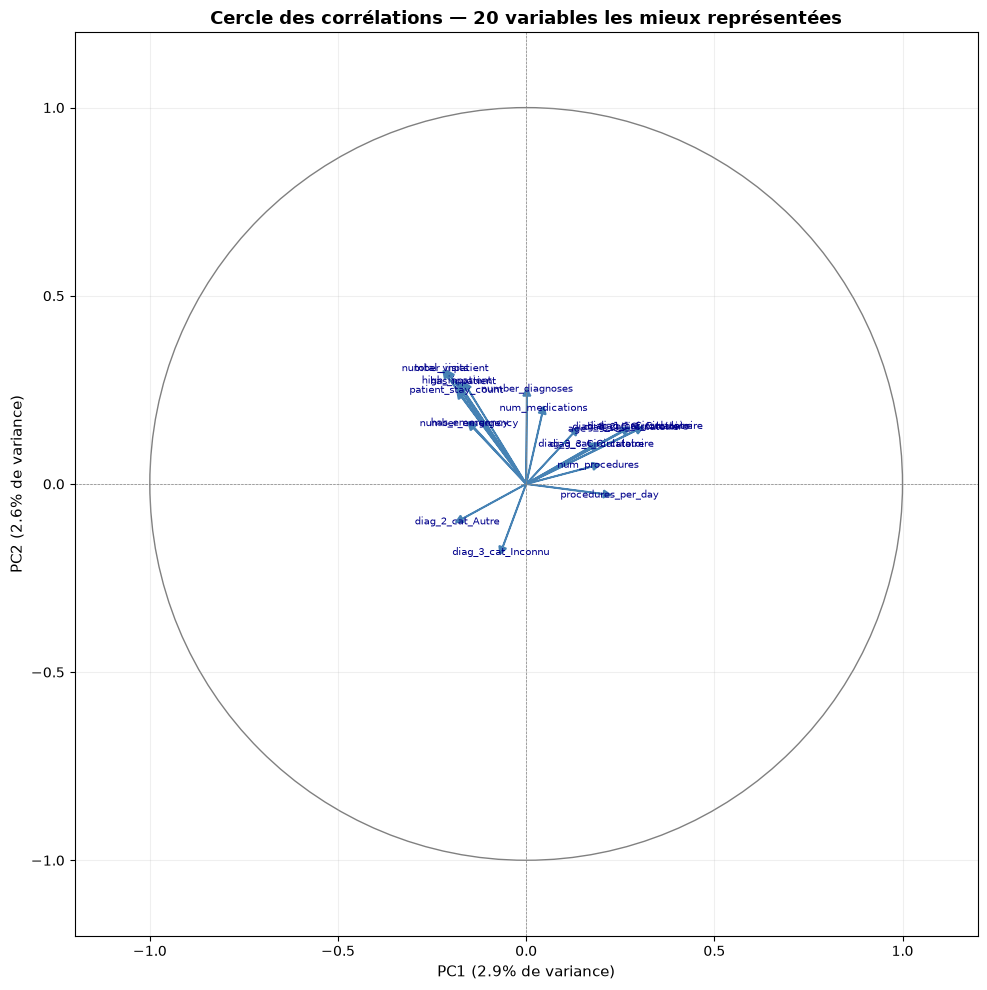

In [113]:
# Coordonnées des variables sur PC1 et PC2
# loadings = correlations entre variables originales et composantes
loadings = pca_modele.components_.T  # shape (n_features, n_components)
coord_pc1 = loadings[:, 0]
coord_pc2 = loadings[:, 1]
noms_variables = X_train.columns.tolist()

# On affiche seulement les N variables les plus représentées (cos2 élevé)
cos2 = coord_pc1**2 + coord_pc2**2
n_top = 20
idx_top = np.argsort(cos2)[::-1][:n_top]

fig, ax = plt.subplots(figsize=(10, 10))

# Cercle de référence
cercle = plt.Circle((0, 0), 1, color='grey', fill=False, linewidth=1)
ax.add_patch(cercle)

for i in idx_top:
    ax.arrow(0, 0, coord_pc1[i], coord_pc2[i],
             head_width=0.02, head_length=0.02,
             fc='steelblue', ec='steelblue', linewidth=1.2)
    ax.text(coord_pc1[i] * 1.08, coord_pc2[i] * 1.08,
            noms_variables[i], fontsize=7, ha='center', va='center', color='darkblue')

ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.axhline(0, color='grey', linewidth=0.5, linestyle='--')
ax.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax.set_xlabel(f'PC1 ({pca_modele.explained_variance_ratio_[0]:.1%} de variance)', fontsize=11)
ax.set_ylabel(f'PC2 ({pca_modele.explained_variance_ratio_[1]:.1%} de variance)', fontsize=11)
ax.set_title(f'Cercle des corrélations — {n_top} variables les mieux représentées',
             fontsize=13, fontweight='bold')
ax.set_aspect('equal')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Le cercle des corrélations permet d'identifier quelles variables médicales contribuent le plus aux deux premières composantes.

- Les variables qui pointent dans la même direction sont positivement corrélées entre elles.
- Les variables proches du centre sont mal représentées dans ce plan à deux dimensions — elles contribuent davantage aux composantes suivantes.

Ce graphique est complémentaire de la carte des individus : il donne le sens médical des axes.


## 6.6 Définition des modèles

Deux modèles de classification sont comparés :

| Modèle | Principe | Paramètre principal |
|---|---|---|
| Arbre de décision | Règles de décision hiérarchiques | profondeur max = 5 |
| KNN | Vote des k voisins les plus proches | k = 11 voisins |

Le KNN est intégré dans un Pipeline avec un StandardScaler car la mesure de distance entre voisins dépend de l'échelle des composantes.
L'arbre de décision est quant à lui insensible à l'échelle des variables.


In [125]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
# Utilisation de grid search pour trouver les meilleurs hyperparamètres pour chaque modèle et chaque jeu de données (brut et ACP).
# ── 1. ARBRE DE DÉCISION sur Variables Brutes ───────────────────────────────
print("1. Arbre de Décision sur Variables Brutes...")
param_grid_dt = {'max_depth': [5, 8, 12, 15], 'min_samples_leaf': [2, 5, 10]}
grid_dt_brut = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_dt, cv=skf, scoring='f1_macro'
)
grid_dt_brut.fit(X_train, y_train)
arbre_brut = grid_dt_brut.best_estimator_
print(f"  Meilleurs params : {grid_dt_brut.best_params_}")
print(f"  Accuracy (test)  : {arbre_brut.score(X_test, y_test):.4f}")

# ── 2. KNN sur Variables Brutes ─────────────────────────────────────────────
print("\n2. KNN sur Variables Brutes...")
np.random.seed(42)
idx_sub = np.random.choice(len(X_train), size=min(10000, len(X_train)), replace=False)
X_tr_sub  = X_train.iloc[idx_sub]
y_tr_sub  = y_train.iloc[idx_sub]

param_grid_knn = {'n_neighbors': [5, 11, 21], 'weights': ['uniform', 'distance']}
grid_knn_brut = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn, cv=skf, scoring='f1_macro'
)
grid_knn_brut.fit(X_tr_sub, y_tr_sub)
knn_brut = grid_knn_brut.best_estimator_
knn_brut.fit(X_train, y_train)
print(f"  Meilleurs params : {grid_knn_brut.best_params_}")
print(f"  Accuracy (test)  : {knn_brut.score(X_test, y_test):.4f}")

# ── 3. ARBRE DE DÉCISION sur Composantes ACP ────────────────────────────────
print("\n3. Arbre de Décision sur Composantes ACP...")
grid_dt_pca = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_dt, cv=skf, scoring='f1_macro'
)
grid_dt_pca.fit(X_train_pca, y_train)
arbre_pca = grid_dt_pca.best_estimator_
print(f"  Meilleurs params : {grid_dt_pca.best_params_}")
print(f"  Accuracy (test)  : {arbre_pca.score(X_test_pca, y_test):.4f}")

# ── 4. KNN sur Composantes ACP ───────────────────────────────────────────────
print("\n4. KNN sur Composantes ACP...")
idx_pca_sub  = np.random.choice(len(X_train_pca), size=min(10000, len(X_train_pca)), replace=False)
X_tr_pca_sub = X_train_pca.iloc[idx_pca_sub]
y_tr_pca_sub = y_train.iloc[idx_pca_sub]

grid_knn_pca = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn, cv=skf, scoring='f1_macro'
)
grid_knn_pca.fit(X_tr_pca_sub, y_tr_pca_sub)
knn_pca = grid_knn_pca.best_estimator_
knn_pca.fit(X_train_pca, y_train)
print(f"  Meilleurs params : {grid_knn_pca.best_params_}")
print(f"  Accuracy (test)  : {knn_pca.score(X_test_pca, y_test):.4f}")


1. Arbre de Décision sur Variables Brutes...
  Meilleurs params : {'max_depth': 5, 'min_samples_leaf': 2}
  Accuracy (test)  : 0.7901

2. KNN sur Variables Brutes...
  Meilleurs params : {'n_neighbors': 11, 'weights': 'uniform'}
  Accuracy (test)  : 0.6553

3. Arbre de Décision sur Composantes ACP...
  Meilleurs params : {'max_depth': 5, 'min_samples_leaf': 5}
  Accuracy (test)  : 0.6263

4. KNN sur Composantes ACP...
  Meilleurs params : {'n_neighbors': 21, 'weights': 'uniform'}
  Accuracy (test)  : 0.5965


## 6.7 Entraînement et prédictions

In [115]:
# Prédictions finales sur le jeu de test (4 modèles)
y_pred_arbre_brut = arbre_brut.predict(X_test)
y_pred_knn_brut   = knn_brut.predict(X_test)
y_pred_arbre_pca  = arbre_pca.predict(X_test_pca)
y_pred_knn_pca    = knn_pca.predict(X_test_pca)

print("Prédictions finales sur le jeu de test terminées.")
print(f"  Arbre (Brut) accuracy : {arbre_brut.score(X_test, y_test):.4f}")
print(f"  KNN   (Brut) accuracy : {knn_brut.score(X_test, y_test):.4f}")
print(f"  Arbre (ACP)  accuracy : {arbre_pca.score(X_test_pca, y_test):.4f}")
print(f"  KNN   (ACP)  accuracy : {knn_pca.score(X_test_pca, y_test):.4f}")


Prédictions finales sur le jeu de test terminées.
  Arbre (Brut) accuracy : 0.7901
  KNN   (Brut) accuracy : 0.6553
  Arbre (ACP)  accuracy : 0.6263
  KNN   (ACP)  accuracy : 0.5965


## 6.8 Affichage de l'arbre de décision

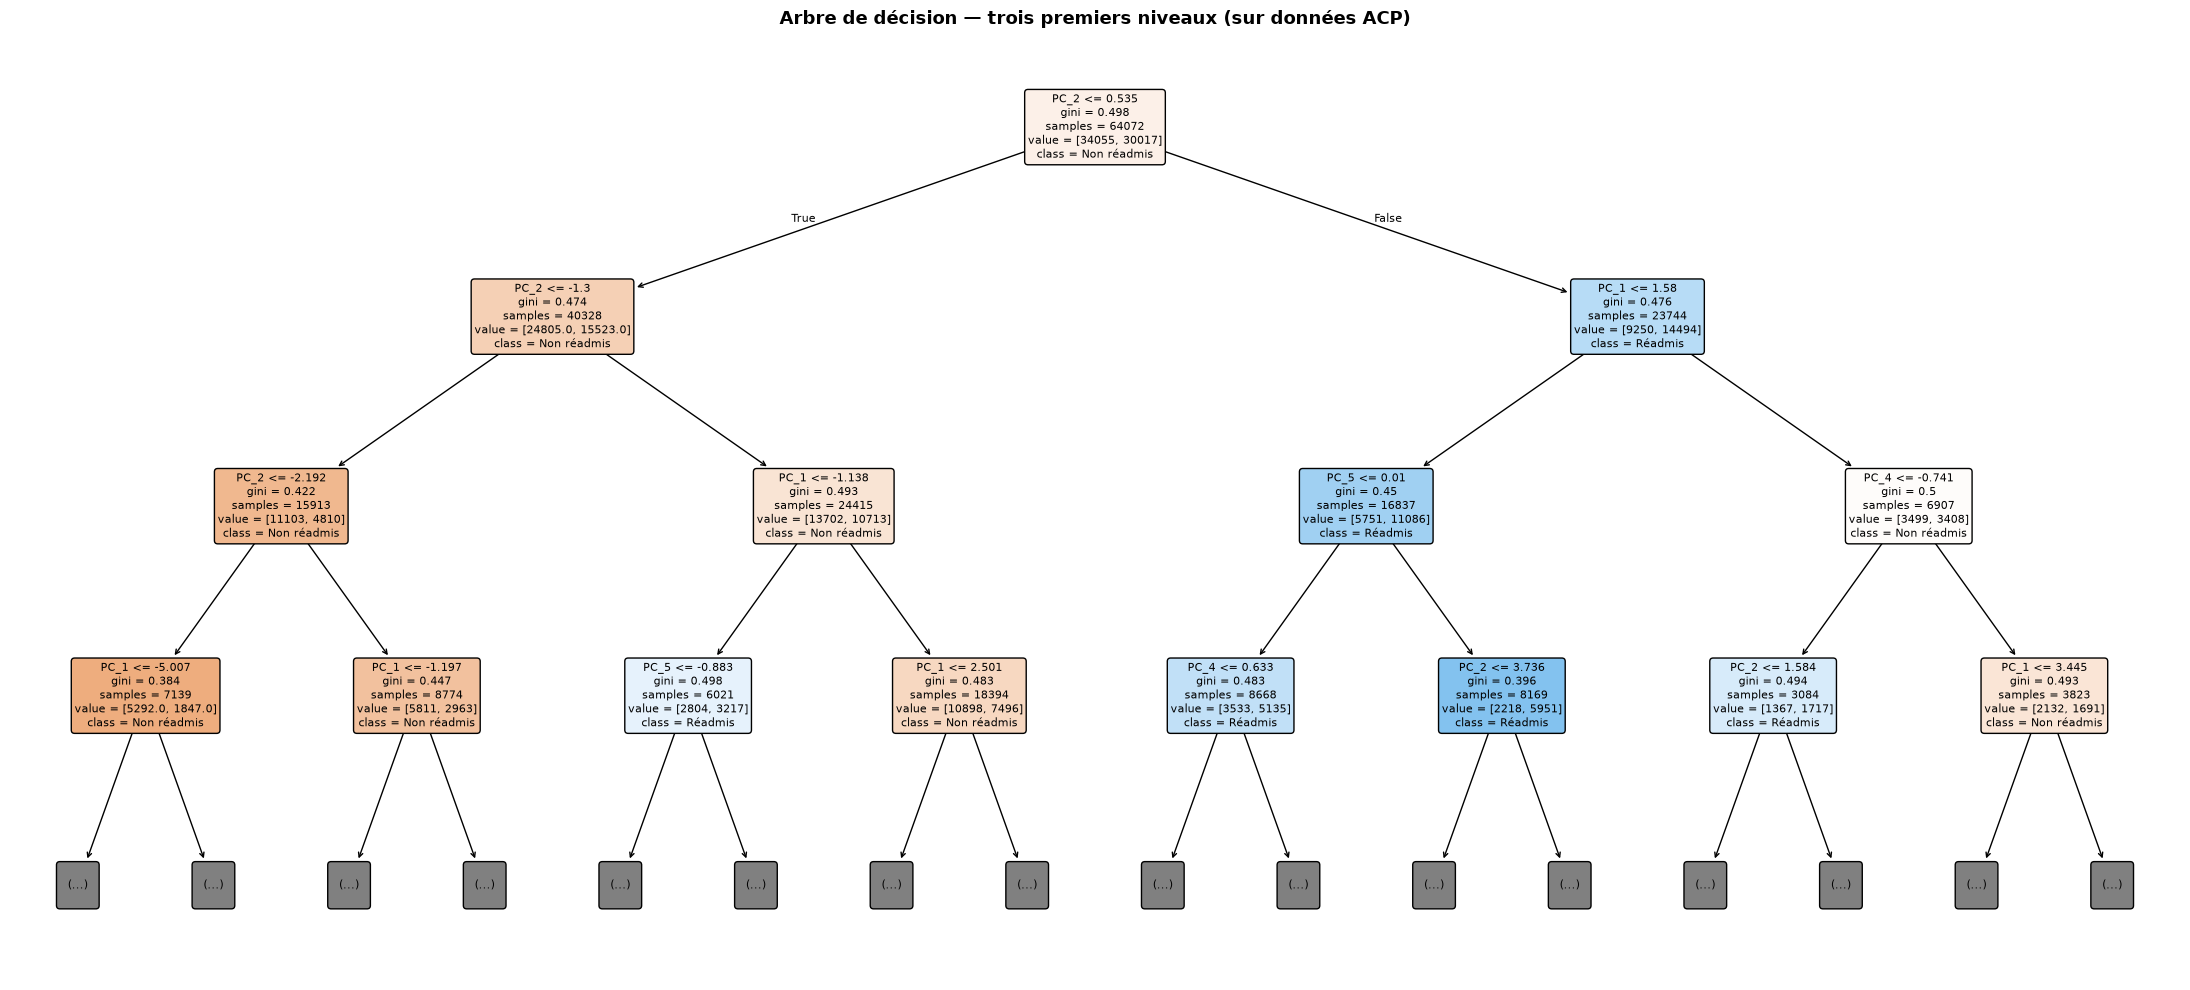

In [116]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    arbre_pca,
    feature_names=X_train_pca.columns,
    class_names=['Non réadmis', 'Réadmis'],
    filled=True, rounded=True, max_depth=3, fontsize=8, ax=ax
)
ax.set_title("Arbre de décision — trois premiers niveaux (sur données ACP)",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


# 7. Évaluation et interprétation

## 7.1 Métriques

| Métrique | Ce qu'elle mesure |
|---|---|
| **Accuracy** | Proportion totale de prédictions correctes |
| **F1 macro** | Moyenne non pondérée du F1 de chaque classe |
| **Rappel classe 1** | Proportion de réadmissions correctement détectées |
| **Précision classe 1** | Parmi les prédictions positives, combien sont réellement réadmis |

Avec une distribution 54/46, l'accuracy est ici une métrique valable.
Le F1 macro reste important pour vérifier que les deux classes sont traitées équitablement.


In [117]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluer(nom, y_true, y_pred):
    """Retourne un dictionnaire de métriques pour un modèle (classification binaire 0/1)."""
    return {
        'Modèle': nom,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Précision': precision_score(y_true, y_pred, zero_division=0),
        'Rappel': recall_score(y_true, y_pred, zero_division=0),
        'F1-score': f1_score(y_true, y_pred, zero_division=0),
    }

print("=== Résultats finaux sur le TEST ===")
res_test = pd.DataFrame([
    evaluer('Arbre de décision (Variables Brutes)', y_test, y_pred_arbre_brut),
    evaluer('KNN (Variables Brutes)',               y_test, y_pred_knn_brut),
    evaluer('Arbre de décision (Composantes ACP)',  y_test, y_pred_arbre_pca),
    evaluer('KNN (Composantes ACP)',                y_test, y_pred_knn_pca),
]).set_index('Modèle').round(4)
display(res_test)

=== Résultats finaux sur le TEST ===


,Accuracy,Précision,Rappel,F1-score
Modèle,,,,
Arbre de décision (Variables Brutes),0.7901,0.8178,0.7102,0.7602
KNN (Variables Brutes),0.6553,0.6724,0.5154,0.5835
Arbre de décision (Composantes ACP),0.6263,0.6341,0.4781,0.5452
KNN (Composantes ACP),0.5965,0.5883,0.4618,0.5175


In [118]:
print("=== Résultats finaux sur le TEST ===")
res_test = pd.DataFrame([
    evaluer('Arbre de décision (Variables Brutes)', y_test, y_pred_arbre_brut),
    evaluer('KNN (Variables Brutes)',               y_test, y_pred_knn_brut),
    evaluer('Arbre de décision (Composantes ACP)',  y_test, y_pred_arbre_pca),
    evaluer('KNN (Composantes ACP)',                y_test, y_pred_knn_pca),
]).set_index('Modèle').round(4)
display(res_test)


=== Résultats finaux sur le TEST ===


,Accuracy,Précision,Rappel,F1-score
Modèle,,,,
Arbre de décision (Variables Brutes),0.7901,0.8178,0.7102,0.7602
KNN (Variables Brutes),0.6553,0.6724,0.5154,0.5835
Arbre de décision (Composantes ACP),0.6263,0.6341,0.4781,0.5452
KNN (Composantes ACP),0.5965,0.5883,0.4618,0.5175


### 7.2 Interprétation des métriques

Avec un jeu de données quasi-équilibré (54/46), un modèle naïf qui prédit toujours la classe majoritaire (0) atteindrait environ 54 % d'accuracy — bien loin de ce qu'on attend.

- **Accuracy** : reflète ici la capacité générale du modèle, car les classes sont équilibrées.
- **F1 macro** : indique si les deux classes sont traitées de manière équivalente. Un F1 macro proche de l'accuracy montre que le modèle ne favorise pas une classe.
- **Rappel classe 1** : fraction des séjours qui ont effectivement mené à une réadmission et que le modèle a détectés. C'est la métrique la plus importante cliniquement.

L'arbre de décision offre une interprétabilité directe sous forme de règles hiérarchiques, tandis que le KNN s'appuie sur la proximité dans l'espace réduit des composantes principales.


## 7.3 Rapports de classification détaillés

In [121]:
from sklearn.metrics import classification_report

noms_classes = ['Non réadmis (0)', 'Réadmis (1)']

for nom, y_pred in [
    ('Arbre de décision (Variables Brutes)', y_pred_arbre_brut),
    ('KNN (Variables Brutes)',               y_pred_knn_brut),
    ('Arbre de décision (Composantes ACP)',  y_pred_arbre_pca),
    ('KNN (Composantes ACP)',                y_pred_knn_pca),
]:
    print(f"{'='*55}")
    print(f"Rapport – {nom}")
    print('='*55)
    print(classification_report(
        y_test, y_pred, labels=[0, 1],
        target_names=noms_classes, zero_division=0
    ))

Rapport – Arbre de décision (Variables Brutes)
                 precision    recall  f1-score   support

Non réadmis (0)       0.77      0.86      0.81     10643
    Réadmis (1)       0.82      0.71      0.76      9380

       accuracy                           0.79     20023
      macro avg       0.79      0.79      0.79     20023
   weighted avg       0.79      0.79      0.79     20023

Rapport – KNN (Variables Brutes)
                 precision    recall  f1-score   support

Non réadmis (0)       0.65      0.78      0.71     10643
    Réadmis (1)       0.67      0.52      0.58      9380

       accuracy                           0.66     20023
      macro avg       0.66      0.65      0.64     20023
   weighted avg       0.66      0.66      0.65     20023

Rapport – Arbre de décision (Composantes ACP)
                 precision    recall  f1-score   support

Non réadmis (0)       0.62      0.76      0.68     10643
    Réadmis (1)       0.63      0.48      0.55      9380

       accu

**Lecture des rapports :**

- **support** : nombre réel d'observations de chaque classe dans le jeu de test.
- **precision** : parmi les séjours prédits réadmis, quelle fraction l'était vraiment.
- **recall** : parmi les vrais réadmis, quelle fraction a été détectée.
- **f1-score** : équilibre entre précision et rappel.

Un bon modèle aura un rappel et une précision élevés pour les deux classes simultanément.


## 7.4 Matrices de confusion

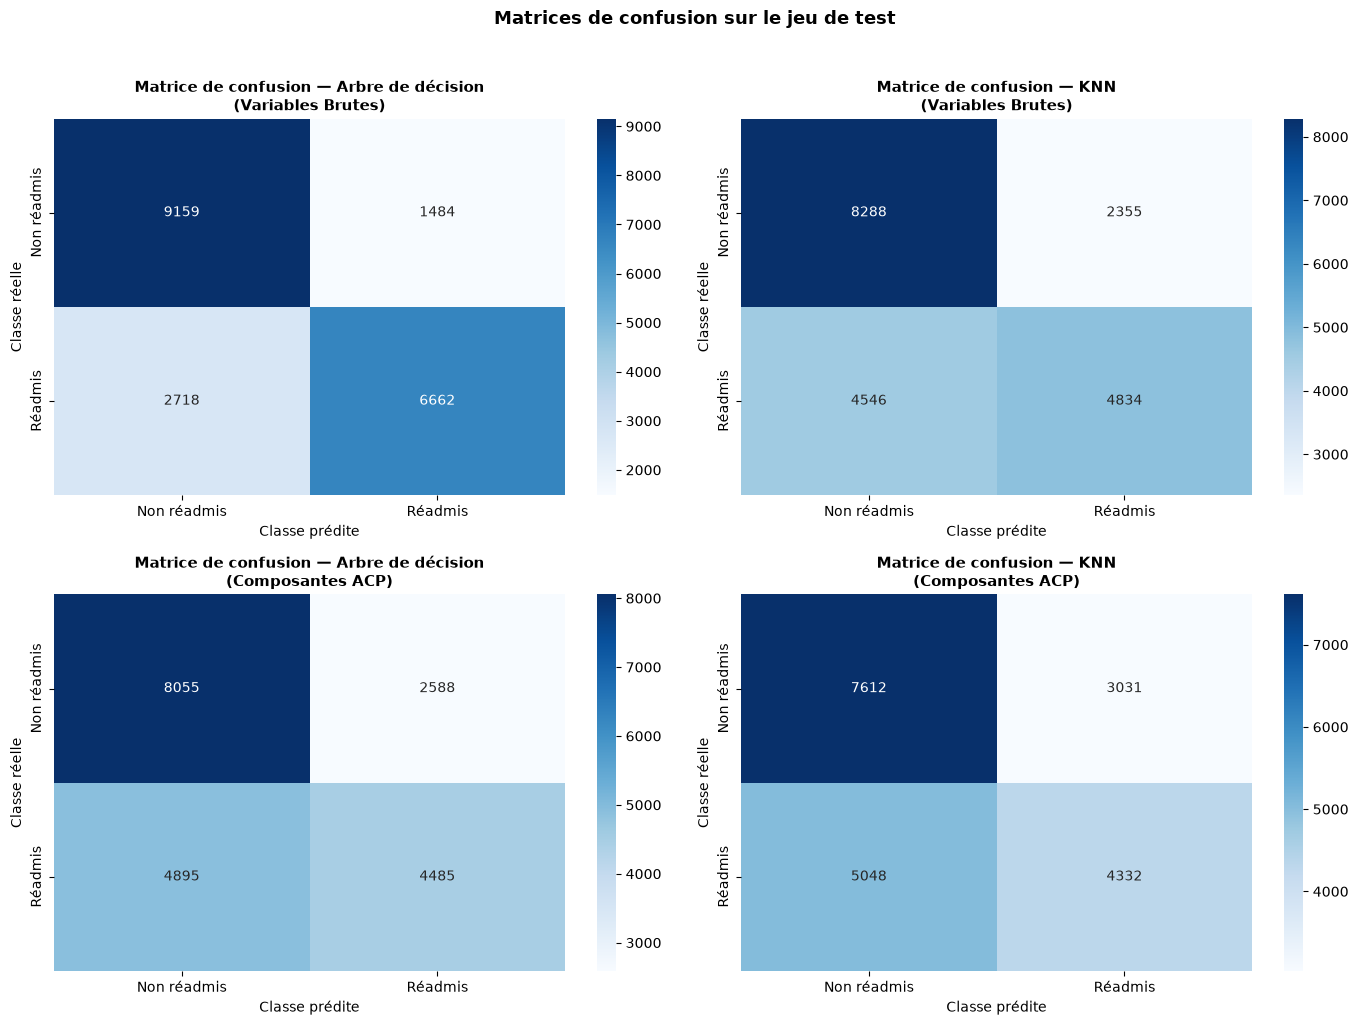

In [123]:
from sklearn.metrics import confusion_matrix


fig, axes = plt.subplots(2, 2, figsize=(14, 10))
etiquettes = ['Non réadmis', 'Réadmis']

modeles_mc = [
    ('Arbre de décision\n(Variables Brutes)', y_pred_arbre_brut),
    ('KNN\n(Variables Brutes)',               y_pred_knn_brut),
    ('Arbre de décision\n(Composantes ACP)',  y_pred_arbre_pca),
    ('KNN\n(Composantes ACP)',                y_pred_knn_pca),
]

for ax, (nom, y_pred) in zip(axes.flatten(), modeles_mc):
    mc = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(mc, annot=True, fmt='d', cmap='Blues',
                xticklabels=etiquettes, yticklabels=etiquettes, ax=ax)
    ax.set_title(f'Matrice de confusion — {nom}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Classe prédite', fontsize=10)
    ax.set_ylabel('Classe réelle', fontsize=10)

plt.suptitle("Matrices de confusion sur le jeu de test", fontsize=13, y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()


**Lecture des matrices :**

Chaque ligne représente la classe réelle, chaque colonne la classe prédite.

- **Vrais négatifs (haut gauche)** : séjours sans réadmission correctement identifiés.
- **Faux positifs (haut droite)** : séjours sans réadmission prédits à tort comme réadmis.
- **Faux négatifs (bas gauche)** : réadmissions manquées par le modèle — l'erreur la plus coûteuse.
- **Vrais positifs (bas droite)** : réadmissions correctement détectées.

Un bon modèle maximise les deux diagonales et minimise les cases hors diagonale, particulièrement les faux négatifs.


## 7.5 Importance des composantes — Arbre de décision

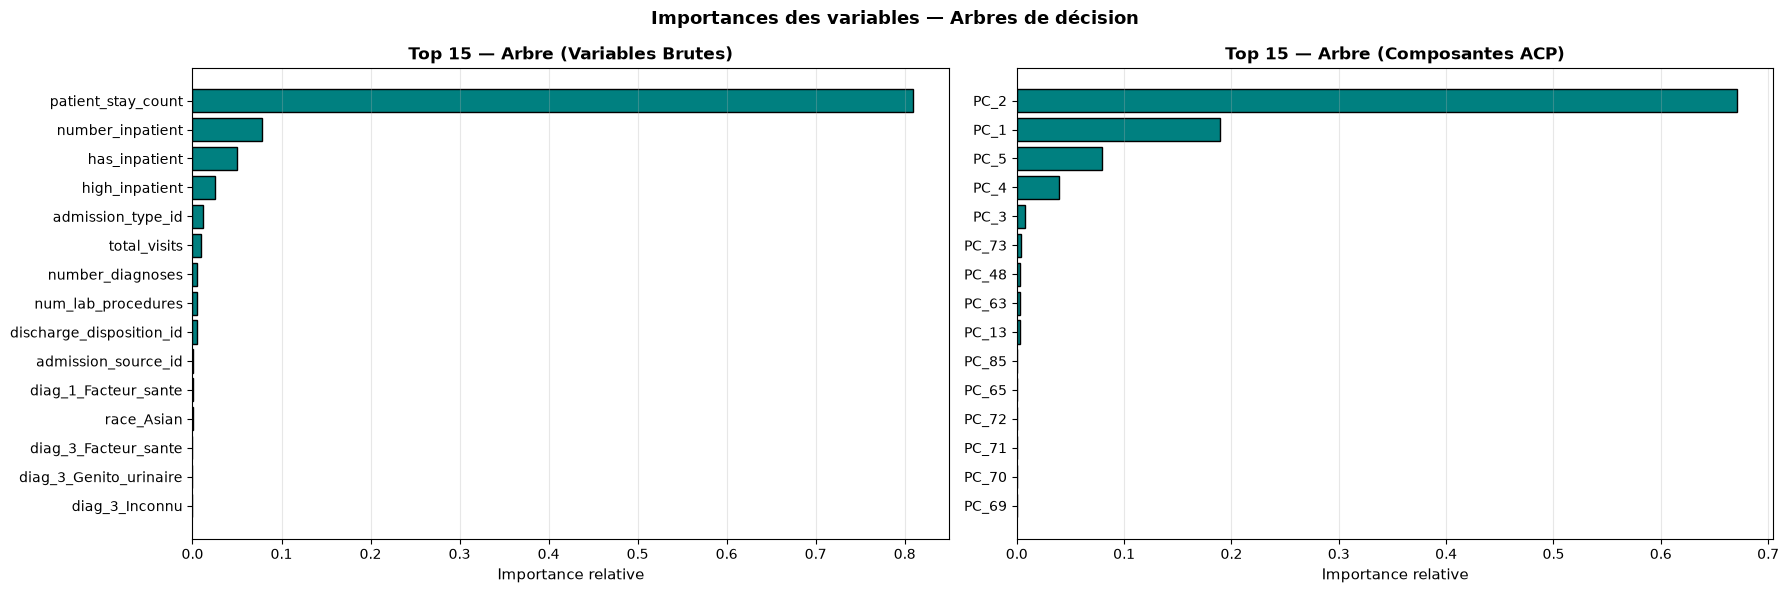


Top 15 — Arbre (Variables Brutes):


,importance
patient_stay_count,0.8093
number_inpatient,0.0782
has_inpatient,0.0496
high_inpatient,0.0252
admission_type_id,0.0113
total_visits,0.0098
number_diagnoses,0.0056
num_lab_procedures,0.0050
discharge_disposition_id,0.0045
admission_source_id,0.0009


In [124]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, (nom, modele, X_cols) in zip(axes, [
    ('Arbre (Variables Brutes)',   arbre_brut, X_train.columns),
    ('Arbre (Composantes ACP)',    arbre_pca,  X_train_pca.columns),
]):
    importances = pd.Series(
        modele.feature_importances_, index=X_cols
    ).sort_values(ascending=False).head(15)
    ax.barh(importances.index[::-1], importances.values[::-1],
            color='teal', edgecolor='black')
    ax.set_title(f"Top 15 — {nom}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Importance relative", fontsize=11)
    ax.grid(axis='x', alpha=0.3)

plt.suptitle("Importances des variables — Arbres de décision", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nTop 15 — Arbre (Variables Brutes):")
display(pd.Series(arbre_brut.feature_importances_, index=X_train.columns)
        .sort_values(ascending=False).head(15).rename('importance').to_frame().round(4))


Ces importances mesurent la réduction d'impureté apportée par chaque composante principale dans l'Arbre de décision.
Les composantes sont des combinaisons linéaires de variables initiales ; leur importance indique les axes factoriels qui séparent le mieux les patients réadmis des non-réadmis.


# 8. Conclusion

## Résumé du travail réalisé

Ce projet a couvert l'ensemble de la chaîne d'analyse sur le jeu de données **Diabetes 130-US Hospitals**.

| Étape | Points clés |
|---|---|
| **Compréhension métier** | Problème clairement posé : prédire si un patient sera réadmis après sa sortie |
| **Exploration** | Valeurs manquantes, valeurs inconnues (`?`), déséquilibre initial de la cible |
| **Préparation** | Nettoyage complet, exclusion des décédés, regroupement des diagnostics ICD-9, encodage one-hot avec regroupement des rares |
| **Variable cible** | Codage binaire `0 = NO`, `1 = >30 ou <30` — distribution quasi-équilibrée (54/46) |
| **Segmentation** | 4 clusters K-Means identifiés avec coude + silhouette — profils médicalement interprétables |
| **ACP** | Réduction de dimension (90 % variance), carte des individus, cercle des corrélations |
| **Classification** | Arbre de décision et KNN comparés sur validation puis évalués sur test |
| **Évaluation** | Accuracy, F1 macro, rappel, matrices de confusion |

## Décisions importantes et justifications

- **Exclusion des patients décédés** : leur `NO` n'est pas un résultat clinique ordinaire. En production, une règle métier retourne directement `0` pour tout séjour terminé par un décès, sans passer par le modèle.
- **Regroupement `>30` et `<30`** : donne une distribution équilibrée, évite le biais vers la classe majoritaire, et pose une question médicale claire — ce patient sera-t-il réadmis ?
- **Gender Unknown** : seulement 3 valeurs (0,003 %) remplacées par le mode (`Female`) — impact négligeable.

